# FIP 18 — The isosbestic correction: what it does to the curated traces

The curated DA and NE traces have had the isosbestic (iso) channel regressed out as a motion
correction. Does that step remove movement artifact, or add iso's noise to the trace, and what does
it change in the analyses that relate DA and NE to movement (`fip_10` §2, `fip_12` §1, `fip_13`)?
The biology stays in the video-latents repo; this notebook is about the processing.

0. Data: every stage of the pipeline, from the processed NWBs
1. What the pipeline fitted: the iso coefficient β, the F0 terms and its own QC
2. Iso physics: spectra, coherence with the sensor, β by frequency band, power the correction adds
   - 2a. Why subtracting adds: one session worked through
   - 2b. The pipeline's β step by step, per fiber-session, against the slope in each band
3. Iso and the red channel against motion energy
4. Fiber events in iso, and the step after task events
5. Downstream: corrected vs bleach-only in the ME analyses
6. The `bright-v2` F0 fit: does the power the correction adds depend on how F0 is fitted?
7. Numbers

**How the curated traces are made** (`aind-fip-dff` release 19.0, commit
[`c1733bb`](https://github.com/AllenNeuralDynamics/aind-fip-dff/tree/c1733bb); all 295
`DANE_bilateral` sessions were processed with it on 2026-11-10/11; plan and background in
`fip_isosbestic_todo.md`). Per channel (G, Iso, R) of each fiber, `tc_brightfit` fits one baseline
F0 to the whole session — a product of up to three decaying exponentials and one rising
"brightening" term, every time constant ≥ 1 s, refit robustly so that it follows the lower edge of
the trace — and ΔF/F = F / F0 − 1 (`dff-bright`). Then per fiber, `motion_correct`:

1. every ΔF/F trace is low-passed at 0.05 Hz, for the fit only;
2. G (and R) is regressed on Iso, robustly, with a loss that forgives points above the line more
   than points below it (Tukey c = 2 above, 4.685 below);
3. the slope β is clipped at ≥ 0 and the intercept discarded — **β = 0 means no correction**;
4. β · (the *unfiltered* Iso ΔF/F, mean removed) is subtracted from the channel;
5. the result is low-passed at 3 Hz (`dff-bright_mc-iso-IRLS`, the curated `data` column).

So β is learned from what iso and the sensor share at periods longer than 20 s and applied at every
frequency. Whether that removes or adds power in a band depends on how much of iso's power in that
band the sensor channel shares (its coherence): for a band,

var(G − β·iso) = var(G) − 2β·cov(G, iso) + β²·var(iso),

where the middle term is the removal (zero without coherence) and the last term is added whatever
iso holds. §2a shows this on one session.

**Signals.** DA: dLight in lateral NAc (`latNAcc(X)-DA`, green channel of the NAc fiber). NE: GCaMP
in LC noradrenergic axons in PL (`PL(X)-LCAxonCa`, green channel of the PL fiber). Each fiber also
has its Iso channel (415 nm excitation read in green) and a red channel (560 nm; a second sensor on
the NAc fiber in some cohorts, sensor-free on the PL fiber). "Corrected" is the pipeline's
`dff-bright_mc-iso-IRLS`; "bleach-only" is `dff-bright` with the same 3 Hz low-pass applied here,
so the two differ only by the subtraction.

**Data.** The same 97 same-side DA/NE pair sessions with bottom-camera ME as `fip_12`
(`fu.inventory_pairs`, `fu.choose_side`, `fu.load_pairs`, `fu.add_motion_energy`), restricted to the
sessions whose processed NWB is on public S3 (`aind-open-data`; the location from the asset's
`df_sess` tables, else `inputs/fip_processed_nwb.csv`). From each NWB: raw, bleach-only and corrected
traces of G, Iso and R of the DA fiber and the NE fiber (`fu.load_nwb_stages`), and the pipeline's
`quality_control.json` (`fu.load_pipeline_qc`). Traces are put on the pair's 20 Hz grid; ME is on
the `floor_sd` scale with onsets from the z-scored trace, as everywhere. The first run reads ~95
NWBs over HTTPS (about 4 s each) into `scratch/fip_18/`.

## Setup

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from scipy import signal as sps
from scipy import stats

import fip_utils as fu
import signal_utils as su
import stats_utils as st
import plot_utils as pu
from plotstyle import apply_style, style_ax, save_fig, PALETTE, OKABE_ITO

apply_style()
warnings.filterwarnings("ignore", message="Mean of empty slice")
warnings.filterwarnings("ignore", message="Sample size too small for normal approximation")
warnings.filterwarnings("ignore", message="Exact p-value calculation does not work if there are zeros")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

In [2]:
DATA_ROOT = fu.DATA_ROOT
PAIRS_CACHE = os.path.join(fu.CACHE_ROOT, "fip", "pairs.pkl")
NWB_CACHE = os.path.join(fu.CACHE_ROOT, "fip_18", "nwb")   # one .npz + .qc.json per NWB
FIG_DIR = os.path.join(fu.FIG_ROOT, "fip")
SAVE_FIG = True

# ── Data ─────────────────────────────────────────────────────────────────────
FS = 20.0
CAMERA = "BottomCamera"
ME_NORM = "floor_sd"
MIN_SESSIONS_PER_ANIMAL = 3
EXCLUDE_SUBJECTS = ()
FS_ONSET = 100.0
ROLES = ("da", "ne")                       # the two fibers of a pair
ROLE_LABEL = {"da": "DA fiber (NAc)", "ne": "NE fiber (PL)"}
STAGES = ("bleach", "corrected")            # bleach = dff-bright + the 3 Hz low-pass; corrected = the pipeline's mc
CHANNELS = ("G", "Iso", "R")

# ── Spectra (§2) ─────────────────────────────────────────────────────────────
NPERSEG = 4096                              # 205 s segments: 0.005 Hz resolution, ≥ 8 bins in the lowest band
BANDS = {"0.01–0.05": (0.01, 0.05), "0.05–0.2": (0.05, 0.2), "0.2–1": (0.2, 1.0), "1–3": (1.0, 3.0)}
PIPELINE_CUTOFF_HZ = 0.05                   # β is fitted below this
EXAMPLE_SPAN_S = 20.0                       # §2a trace excerpt
EXAMPLE_BAND = "1–3"
STEP_BANDS = {b: BANDS[b] for b in BANDS if b != "0.01–0.05"}   # §2b: band slopes beyond the fit bands (fu.BETA_FIT_BANDS)

# ── ME (§3, §5) ──────────────────────────────────────────────────────────────
XCORR_MAXLAG = 3.0
ETA_LAGS = np.arange(-2.0, 3.0 + 1e-9, 1 / FS)
PRE_WIN = (-1.0, -0.2)                      # response = mean over RESP_WIN − mean over PRE_WIN
RESP_WIN = (0.0, 1.0)

# ── Fiber events (§4) ────────────────────────────────────────────────────────
EVENT_SD = 30.0                             # robust SD above which an iso excursion counts as a fiber event
EVENT_MASK_S = 30.0                         # proposed rule: mask ± this around each event
STEP_LAGS = np.arange(-2.0, 8.0 + 1e-9, 1 / FS)
STEP_BASE = (-1.0, 0.0)

# ── Colors ───────────────────────────────────────────────────────────────────
SENSOR_COLOR = {"da": OKABE_ITO["vermillion"], "ne": OKABE_ITO["blue"]}
CH_COLOR = {"Iso": OKABE_ITO["reddish_purple"], "R": OKABE_ITO["orange"]}
ME_COLOR = "0.25"
STAGE_LS = {"bleach": "--", "corrected": "-"}
STAGE_LABEL = {"bleach": "bleach-only", "corrected": "corrected"}

## 0. Data

Pairs as in `fip_12`, then every stage of both fibers from the processed NWB. Two checks follow:
that the corrected trace is reproduced from the bleach-only stages and the pipeline's own β (so
the description above is the code that ran), and how close the curated `data` column is to the
NWB's corrected trace (the curated asset in use may have been built from an earlier processing
run; everything below uses the NWB's own stages, so the two variants always come from one run).

In [3]:
asset_roots = fu.fip_asset_roots(DATA_ROOT)
inv = fu.inventory_pairs(asset_roots)
kept, side_table = fu.choose_side(inv, MIN_SESSIONS_PER_ANIMAL)
all_pairs = fu.load_pairs(kept, fs=FS, cache_path=PAIRS_CACHE)
pairs_me = fu.add_motion_energy(all_pairs, kept, CAMERA, DATA_ROOT, onset_fs=FS_ONSET,
                                exclude_subjects=EXCLUDE_SUBJECTS, me_norm=ME_NORM)

nwb_loc = fu.processed_nwb_locations(asset_roots).set_index("session")
have_nwb = [p for p in pairs_me if p["session"] in nwb_loc.index]
print(f"{len(pairs_me)} sessions with ME; {len(have_nwb)} with a public processed NWB "
      f"(processed {sorted(nwb_loc.loc[[p['session'] for p in have_nwb], 'processed'].unique())})")
missing = [p["session"] for p in pairs_me if p["session"] not in nwb_loc.index]
if missing:
    print("no public NWB:", ", ".join(missing))

FIP asset 3ch: /Users/mib/Documents/Code/data/results-a278f830-9bf2-48e8-9928-a2ff78e4818f
FIP asset 4ch: /Users/mib/Documents/Code/data/results-ddcccb0f-f18f-44a6-a2b1-caba680d28a1/data


loaded 97 pairs from cache /Users/mib/Documents/Code/kinematics_analysis/scratch/fip/pairs.pkl


88 sessions with ME; 85 with a public processed NWB (processed ['2026-11-10', '2026-11-11'])
no public NWB: 818585_2026-01-20, 818586_2026-01-02, 818586_2026-01-30


In [4]:
def fetch_stages(p, row):
    # every channel and stage of the pair's two fibers, on the pair grid, plus the pipeline's QC rows
    s3 = nwb_loc.loc[p["session"], "s3_location"]
    fiber = fu.fiber_of_events(row.path)
    roles = {"da": fiber[row.da_event], "ne": fiber[row.ne_event]}
    raw = fu.load_nwb_stages(s3, sorted(set(roles.values())), cache_dir=NWB_CACHE)
    qc = fu.load_pipeline_qc(s3, cache_dir=NWB_CACHE)
    t = raw["t"] + fu.session_time_offset(row.path)
    grid = p["t0"] + np.arange(len(p["da"])) / FS
    q = dict(p, fiber=roles, qc=qc[qc["fiber"].isin(roles.values())].assign(
        role=lambda d: d["fiber"].map({v: k for k, v in roles.items()})), x={}, beta={})
    for role, f in roles.items():
        for ch in CHANNELS:
            b = raw[(f, ch, "dff-bright")]
            stage_traces = {"raw": raw[(f, ch, "raw")], "bleach_unfiltered": b,
                            "bleach": fu.noise_lowpass(np.nan_to_num(b), FS),
                            "corrected": raw[(f, ch, "dff-bright_mc-iso-IRLS")]}
            for stage, y in stage_traces.items():
                ok = np.isfinite(y)
                q["x"][(role, ch, stage)] = np.interp(grid, t[ok], y[ok]).astype(np.float32)
            if ch != "Iso":
                q["beta"][(role, ch)] = float(qc.set_index(["fiber", "channel"]).loc[(f, ch), "beta"])
    # check 1: the pipeline's corrected G from its bleach-only G and Iso and its β (NWB clock, full session)
    f = roles["ne"]
    g, iso, mc = (raw[(f, "G", "dff-bright")], raw[(f, "Iso", "dff-bright")], raw[(f, "G", "dff-bright_mc-iso-IRLS")])
    rep = fu.noise_lowpass(g - q["beta"][("ne", "G")] * (iso - np.nanmean(iso)), FS)
    q["check_reproduce"] = float(np.nanmax(np.abs(rep - mc)))
    # §2b: the pipeline's β fit step by step and the band slopes, full recording (what the pipeline fitted)
    q["beta_steps"] = {}
    for role, f in roles.items():
        g, iso = raw[(f, "G", "dff-bright")], raw[(f, "Iso", "dff-bright")]
        ok = np.isfinite(g) & np.isfinite(iso)
        q["beta_steps"][role] = fu.iso_beta_steps(g[ok].astype(float), iso[ok].astype(float), FS, bands=STEP_BANDS)
    # check 2: the curated trace against the NWB's corrected trace, on the grid
    q["check_curated_r"] = {role: float(np.corrcoef(p[role], q["x"][(role, "G", "corrected")])[0, 1])
                            for role in ROLES}
    return q


pairs = []
rows_by_session = {r.session: r for r in kept.itertuples()}
for i, p in enumerate(have_nwb):
    pairs.append(fetch_stages(p, rows_by_session[p["session"]]))
    if (i + 1) % 20 == 0:
        print(f"  {i + 1} / {len(have_nwb)}")

SUBJECTS = sorted({p["subject"] for p in pairs})
N_ANIMALS = len(SUBJECTS)
STYLES = pu.animal_styles(SUBJECTS)
print(f"{len(pairs)} sessions, {N_ANIMALS} animals")
pd.Series([p["subject"] for p in pairs]).value_counts().sort_index().rename("sessions").to_frame().T

  20 / 85


  40 / 85


  60 / 85


  80 / 85


85 sessions, 9 animals


,800886,808054,809487,809491,815334,816212,816214,818585,818586
sessions,4,15,8,19,3,5,5,6,20


In [5]:
rep = np.array([p["check_reproduce"] for p in pairs])
r_cur = pd.DataFrame([dict(session=p["session"], **{f"r_{k}": v for k, v in p["check_curated_r"].items()}) for p in pairs])
print(f"check 1 — corrected NE reproduced from bleach-only G, Iso and β: max |difference| over sessions "
      f"{rep.max():.1e} dF/F (exact)")
print(f"check 2 — curated `data` vs the NWB's corrected trace, r: DA median {r_cur['r_da'].median():.4f} "
      f"(min {r_cur['r_da'].min():.3f}), NE median {r_cur['r_ne'].median():.4f} (min {r_cur['r_ne'].min():.3f})")
off = r_cur[(r_cur["r_da"] < 0.99) | (r_cur["r_ne"] < 0.99)]
print(f"   {len(off)} sessions with r < 0.99 on either fiber: the curated asset was built from an earlier processing run than the public NWB."
      " Both variants below come from the NWB.")
if len(off):
    print(off.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

check 1 — corrected NE reproduced from bleach-only G, Iso and β: max |difference| over sessions 6.9e-17 dF/F (exact)
check 2 — curated `data` vs the NWB's corrected trace, r: DA median 0.9986 (min 0.142), NE median 0.9941 (min 0.024)
   32 sessions with r < 0.99 on either fiber: the curated asset was built from an earlier processing run than the public NWB. Both variants below come from the NWB.
          session  r_da  r_ne
800886_2025-08-28 0.999 0.968
800886_2025-09-05 1.000 0.982
800886_2025-09-11 0.991 0.977
818585_2025-12-22 0.999 0.943
818586_2025-12-22 1.000 0.988
818586_2026-01-05 0.999 0.635
808054_2025-09-02 0.993 0.864
808054_2025-09-03 0.142 0.024
808054_2025-09-04 0.558 0.358
808054_2025-09-05 0.420 0.319
808054_2025-09-08 0.451 0.352
808054_2025-09-10 0.995 0.978
808054_2025-09-11 0.993 0.988
808054_2025-09-12 1.000 0.962
808054_2025-09-18 0.997 0.936
808054_2025-09-22 1.000 0.938
808054_2025-09-26 0.998 0.941
809487_2025-09-22 0.998 0.759
809487_2025-09-24 0.997 0.884
8

## 1. What the pipeline fitted

From each session's `quality_control.json`: the iso coefficient β for G and R, the noise
inflation it caused (SD of the corrected over the uncorrected trace, after the 3 Hz filter), the
F0 terms the model selection kept, the calibration ratio of the F0 fit (median negative residual
over the Gaussian expectation; ≈ 1 when F0 sits on the noise), and the evaluation status (worst
channel of the session wins, over all four fibers).

What to look for: β = 0 fiber-sessions, which were never corrected; how different the two fibers
are; and whether noise inflation tracks β.

In [6]:
qc_all = pd.concat([p["qc"].assign(subject=p["subject"], session=p["session"]) for p in pairs], ignore_index=True)
qc_g = qc_all[qc_all["channel"] == "G"].copy()
qc_g["beta_zero"] = qc_g["beta"] <= 0
qc_g["has_bright"] = qc_g["b_bright"] > 0
qc_g["has_rapid"] = qc_g["b_rapid"] != 0

summary = qc_g.groupby("role").agg(n=("beta", "size"), beta_median=("beta", "median"),
                                   beta_zero=("beta_zero", "sum"), noise_inflation_median=("noise_inflation", "median"),
                                   with_brightening=("has_bright", "mean"), with_3rd_exp=("has_rapid", "mean"),
                                   calibration_median=("calibration_ratio", "median"))
print("sensor (G) channel per fiber-session:")
print(summary.to_string(float_format=lambda v: f"{v:.3g}"))
print()
print("β = 0 (no correction) by animal and fiber:")
print(qc_g.groupby(["role", "subject"])["beta_zero"].agg(["sum", "size"]).unstack(0).to_string())
print()
print("evaluation status (whole session, all four fibers):", qc_all.drop_duplicates("session")["status"].value_counts().to_dict())

sensor (G) channel per fiber-session:
       n  beta_median  beta_zero  noise_inflation_median  with_brightening  with_3rd_exp  calibration_median
role                                                                                                        
da    85       0.0281         41                       1             0.141         0.459               0.632
ne    85         1.11          3                     1.5             0.212           0.4                1.15

β = 0 (no correction) by animal and fiber:
        sum    size    
role     da ne   da  ne
subject                
800886    0  0    4   4
808054    7  0   15  15
809487    6  0    8   8
809491    0  0   19  19
815334    1  0    3   3
816212    0  0    5   5
816214    4  3    5   5
818585    3  0    6   6
818586   20  0   20  20

evaluation status (whole session, all four fibers): {'Fail': 85}


/Users/mib/Documents/Code/kinematics_analysis/code/plotstyle.py:190: UserWarning: Glyph 8311 (\N{SUPERSCRIPT SEVEN}) missing from font(s) Arial.
  fig.savefig(fig_dir / f"{name}.{ext}")


/Users/mib/Documents/Code/kinematics_analysis/.venv-fip/lib/python3.12/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 8311 (\N{SUPERSCRIPT SEVEN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


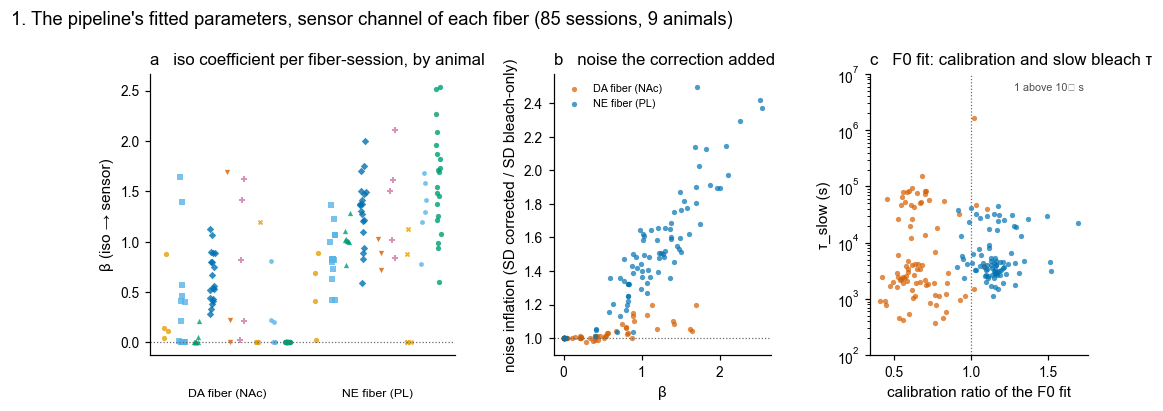

In [7]:
fig = plt.figure(figsize=(11, 3.6))
gs = GridSpec(1, 3, figure=fig, wspace=0.4, top=0.82, width_ratios=[1.4, 1, 1])

ax = fig.add_subplot(gs[0])
for k, role in enumerate(ROLES):
    d = qc_g[qc_g["role"] == role]
    for j, s in enumerate(SUBJECTS):
        v = d.loc[d["subject"] == s, "beta"].to_numpy()
        x = k * (N_ANIMALS + 1) + j
        ax.scatter(np.full(len(v), x) + np.random.default_rng(j).uniform(-0.2, 0.2, len(v)), v,
                   s=12, color=STYLES[s][0], marker=STYLES[s][1], alpha=0.8, lw=0)
    ax.text(k * (N_ANIMALS + 1) + N_ANIMALS / 2 - 0.5, -0.12, ROLE_LABEL[role], ha="center", va="top",
            transform=ax.get_xaxis_transform(), fontsize=8)
ax.axhline(0, color=PALETTE["neutral"], lw=0.8, ls=":")
ax.set_xticks([])
ax.set_ylabel("β (iso → sensor)")
ax.set_title("a   iso coefficient per fiber-session, by animal", loc="left")
style_ax(ax)

ax = fig.add_subplot(gs[1])
for role in ROLES:
    d = qc_g[qc_g["role"] == role]
    ax.scatter(d["beta"], d["noise_inflation"], s=12, color=SENSOR_COLOR[role], alpha=0.7, lw=0, label=ROLE_LABEL[role])
ax.axhline(1, color=PALETTE["neutral"], lw=0.8, ls=":")
ax.set_xlabel("β")
ax.set_ylabel("noise inflation (SD corrected / SD bleach-only)")
ax.set_title("b   noise the correction added", loc="left")
ax.legend(fontsize=7)
style_ax(ax)

ax = fig.add_subplot(gs[2])
for role in ROLES:
    d = qc_g[qc_g["role"] == role]
    ax.scatter(d["calibration_ratio"], d["t_slow"], s=12, color=SENSOR_COLOR[role], alpha=0.7, lw=0)
ax.axvline(1, color=PALETTE["neutral"], lw=0.8, ls=":")
ax.set_yscale("log")
n_off = int((qc_g["t_slow"] > 1e7).sum())
ax.set_ylim(1e2, 1e7)
if n_off:
    ax.text(0.98, 0.97, f"{n_off} above 10⁷ s", transform=ax.transAxes, ha="right", va="top", fontsize=7, color="0.3")
ax.set_xlabel("calibration ratio of the F0 fit")
ax.set_ylabel("τ_slow (s)")
ax.set_title("c   F0 fit: calibration and slow bleach τ", loc="left")
style_ax(ax)
fig.suptitle(f"1. The pipeline's fitted parameters, sensor channel of each fiber ({len(pairs)} sessions, {N_ANIMALS} animals)", x=0.01, ha="left")
save_fig(fig, "fip_18_1_pipeline_fit", fig_dir=FIG_DIR, save=SAVE_FIG)
plt.show()

## 2. Iso physics

Per fiber-session, from the bleach-only (unfiltered) traces: the power spectrum of Iso, G and R
(Welch, 205 s segments); the coherence of Iso with G by band; β by band — the slope of G on Iso
restricted to the band, Re Σ P_GI / Σ P_II, which is the pipeline's regression if it had been done
in that band; and the power ratio of corrected to bleach-only G by band, which the identity in the
header predicts from coherence and β.

What to look for: whether Iso's spectrum above 0.2 Hz sits on the noise floor (flat, like R's on the
NE fiber); whether coherence with G falls to the estimator's floor above the pipeline's 0.05 Hz
cutoff; whether β in the fast bands matches the slow β the pipeline applied; and whether the power
ratio exceeds 1 (power added) in the bands the ME analyses use.

In [8]:
def band_mask(f, band):
    lo, hi = BANDS[band]
    return (f >= lo) & (f < hi)


def welch(x):
    return sps.welch(x - x.mean(), fs=FS, nperseg=NPERSEG)


spectra = {(role, ch): [] for role in ROLES for ch in CHANNELS}    # (subject, PSD) of bleach-only traces
spectra.update({(role, "G corrected"): [] for role in ROLES})
rows = []
for p in pairs:
    for role in ROLES:
        g = p["x"][(role, "G", "bleach_unfiltered")]
        iso = p["x"][(role, "Iso", "bleach_unfiltered")]
        f, p_gg = welch(g)
        _, p_ii = welch(iso)
        _, p_gi = sps.csd(iso - iso.mean(), g - g.mean(), fs=FS, nperseg=NPERSEG)
        _, coh = sps.coherence(iso, g, fs=FS, nperseg=NPERSEG)
        _, p_mc = welch(p["x"][(role, "G", "corrected")])
        _, p_bl = welch(p["x"][(role, "G", "bleach")])
        for ch in CHANNELS:
            spectra[(role, ch)].append((p["subject"], welch(p["x"][(role, ch, "bleach_unfiltered")])[1]))
        spectra[(role, "G corrected")].append((p["subject"], p_mc))
        r = dict(subject=p["subject"], session=p["session"], role=role, beta=p["beta"][(role, "G")])
        for band in BANDS:
            m = band_mask(f, band)
            r[f"coh|{band}"] = coh[m].mean()
            r[f"beta|{band}"] = np.real(p_gi[m].sum()) / p_ii[m].sum()
            r[f"ratio|{band}"] = p_mc[m].sum() / p_bl[m].sum()
            r[f"iso_share|{band}"] = p_ii[m].sum() / p_gg[m].sum()   # Iso power relative to G's, same band
        rows.append(r)
band_sess = pd.DataFrame(rows)
band_animal = {role: st.animal_means(band_sess[band_sess["role"] == role],
                                     ["beta"] + [c for c in band_sess if "|" in c], by_session=False) for role in ROLES}
FREQ = f
coh_floor = 1.0 / (len(pairs[0]["da"]) / (NPERSEG / 2))   # ≈ 1 / number of segments: coherence of unrelated signals
print(f"coherence floor for unrelated signals ≈ {coh_floor:.3f}")
for role in ROLES:
    print(f"── {ROLE_LABEL[role]}, median over animals")
    print(pd.DataFrame({b: {k: band_animal[role][f"{k}|{b}"].median() for k in ("coh", "beta", "ratio", "iso_share")}
                        for b in BANDS}).to_string(float_format=lambda v: f"{v:.3f}"))

coherence floor for unrelated signals ≈ 0.023
── DA fiber (NAc), median over animals
           0.01–0.05  0.05–0.2  0.2–1    1–3
coh            0.124     0.218  0.157  0.052
beta           1.023     0.967 -3.271 -0.764
ratio          0.995     1.000  1.003  1.002
iso_share      0.005     0.008  0.004  0.019
── NE fiber (PL), median over animals
           0.01–0.05  0.05–0.2  0.2–1    1–3
coh            0.140     0.089  0.057  0.027
beta           0.754    -0.551 -0.344 -0.011
ratio          0.982     1.066  1.324  2.291
iso_share      0.061     0.059  0.151  0.915


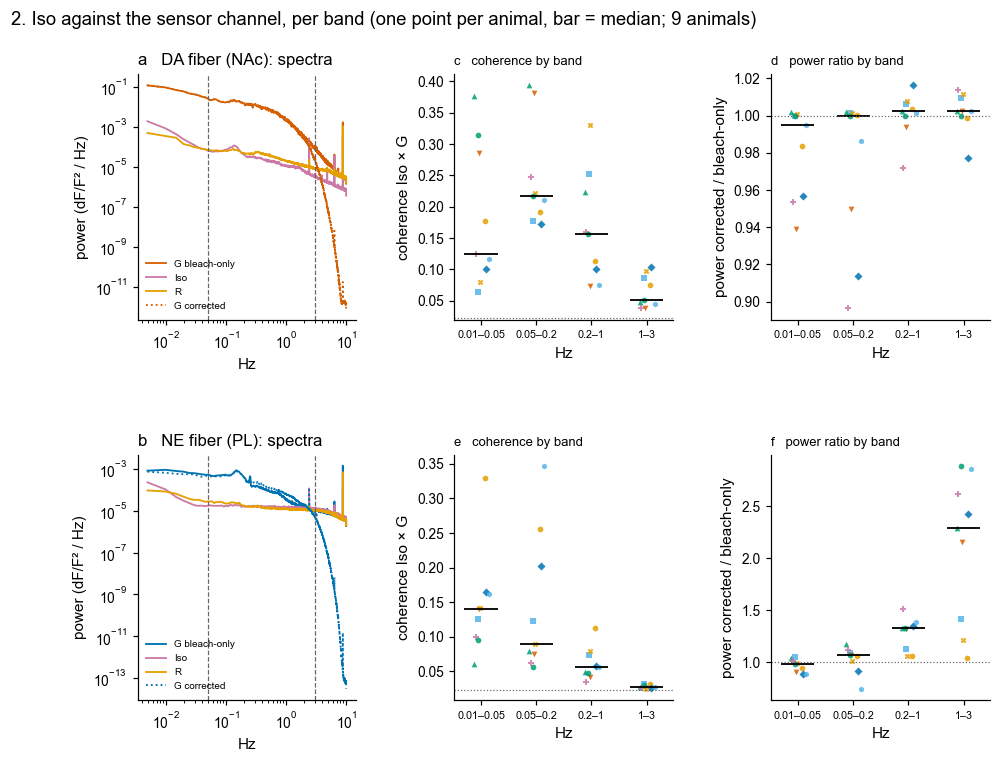

In [9]:
def median_psd(entries):
    subj, psd = zip(*entries)
    return np.median(st.group_means(psd, subj)[1], axis=0)   # median over animals of their mean PSD


fig = plt.figure(figsize=(10, 7.2))
gs = GridSpec(2, 3, figure=fig, wspace=0.45, hspace=0.55, top=0.9)
for k, role in enumerate(ROLES):
    ax = fig.add_subplot(gs[k, 0])
    for ch, color, label in (("G", SENSOR_COLOR[role], "G bleach-only"), ("Iso", CH_COLOR["Iso"], "Iso"), ("R", CH_COLOR["R"], "R")):
        ax.loglog(FREQ[1:], median_psd(spectra[(role, ch)])[1:], color=color, lw=1.2, label=label)
    ax.loglog(FREQ[1:], median_psd(spectra[(role, "G corrected")])[1:], color=SENSOR_COLOR[role], lw=1.2, ls=":", label="G corrected")
    ax.axvline(PIPELINE_CUTOFF_HZ, color=PALETTE["neutral"], lw=0.8, ls="--")
    ax.axvline(fu.NOISE_LOWPASS_HZ, color=PALETTE["neutral"], lw=0.8, ls="--")
    ax.set_xlabel("Hz")
    ax.set_ylabel("power (dF/F² / Hz)")
    ax.set_title(f"{'ab'[k]}   {ROLE_LABEL[role]}: spectra", loc="left")
    ax.legend(fontsize=6.5)
    style_ax(ax)

    for j, (key, ylabel, title, ref) in enumerate((
            ("coh", "coherence Iso × G", "coherence by band", coh_floor),
            ("ratio", "power corrected / bleach-only", "power ratio by band", 1.0))):
        ax = fig.add_subplot(gs[k, j + 1])
        d = band_animal[role]
        for i, band in enumerate(BANDS):
            v = d[f"{key}|{band}"]
            for s in d.index:
                ax.scatter(i + np.random.default_rng(hash(s) % 1000).uniform(-0.15, 0.15), v[s], s=14,
                           color=STYLES[s][0], marker=STYLES[s][1], lw=0, alpha=0.85)
            ax.hlines(v.median(), i - 0.3, i + 0.3, color="k", lw=1.2)
        if ref is not None:
            ax.axhline(ref, color=PALETTE["neutral"], lw=0.8, ls=":")
        ax.set_xticks(range(len(BANDS)))
        ax.set_xticklabels(list(BANDS), fontsize=7)
        ax.set_xlabel("Hz")
        ax.set_ylabel(ylabel)
        ax.set_title(f"{'cdef'[k * 2 + j]}   {title}", loc="left", fontsize=8.5)
        style_ax(ax)
fig.suptitle(f"2. Iso against the sensor channel, per band (one point per animal, bar = median; {N_ANIMALS} animals)", x=0.01, ha="left")
save_fig(fig, "fip_18_2_iso_physics", fig_dir=FIG_DIR, save=SAVE_FIG)
plt.show()

β fitted within each band against the β the pipeline applied, one point per fiber-session. On the
line y = x, the band agrees with the pipeline's β; the fiber-sessions with β = 0 (never corrected)
sit at x = 0. Points outside the panel's range are drawn at its edge as triangles.

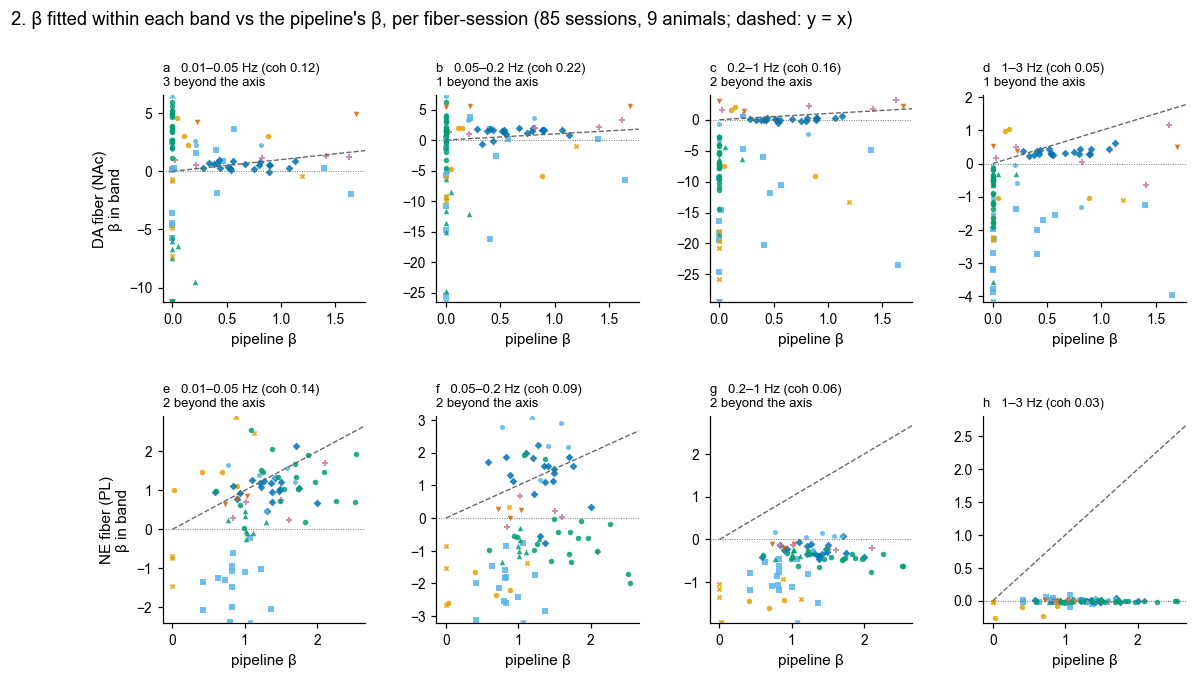

In [10]:
fig, axes = plt.subplots(2, len(BANDS), figsize=(12, 6.4), gridspec_kw=dict(wspace=0.35, hspace=0.55, top=0.86))
for k, role in enumerate(ROLES):
    d = band_sess[band_sess["role"] == role]
    xmax = d["beta"].max() * 1.05
    for j, band in enumerate(BANDS):
        ax = axes[k, j]
        y = d[f"beta|{band}"].to_numpy()
        lo, hi = np.nanpercentile(y, [2, 98])
        lo, hi = min(lo, -0.2), max(hi, xmax)
        pad = 0.05 * (hi - lo)
        lo, hi = lo - pad, hi + pad
        x = d["beta"].to_numpy()
        for s in SUBJECTS:
            m = (d["subject"] == s).to_numpy()
            inside = m & (y >= lo) & (y <= hi)
            ax.scatter(x[inside], y[inside], s=13, color=STYLES[s][0], marker=STYLES[s][1], lw=0, alpha=0.85)
            ax.scatter(x[m & (y < lo)], np.full((m & (y < lo)).sum(), lo), s=18, color=STYLES[s][0], marker="v", lw=0, alpha=0.85)
            ax.scatter(x[m & (y > hi)], np.full((m & (y > hi)).sum(), hi), s=18, color=STYLES[s][0], marker="^", lw=0, alpha=0.85)
        ax.plot([0, xmax], [0, xmax], color=PALETTE["neutral"], lw=0.9, ls="--")
        ax.axhline(0, color=PALETTE["neutral"], lw=0.6, ls=":")
        ax.set_xlim(-0.05 * xmax, xmax)
        ax.set_ylim(lo, hi)
        n_out = int(((y < lo) | (y > hi)).sum())
        med = np.median(band_animal[role][f"coh|{band}"])
        ax.set_title(f"{'abcdefgh'[k * len(BANDS) + j]}   {band} Hz (coh {med:.2f})" + (f"\n{n_out} beyond the axis" if n_out else ""),
                     loc="left", fontsize=8.5)
        ax.set_xlabel("pipeline β")
        if j == 0:
            ax.set_ylabel(f"{ROLE_LABEL[role]}\nβ in band")
        style_ax(ax)
fig.suptitle(f"2. β fitted within each band vs the pipeline's β, per fiber-session ({len(pairs)} sessions, {N_ANIMALS} animals; dashed: y = x)",
             x=0.01, ha="left")
save_fig(fig, "fip_18_2_beta_by_band", fig_dir=FIG_DIR, save=SAVE_FIG)
plt.show()

### 2a. Why subtracting adds: one session

One NE fiber-session with a typical β, and one DA fiber-session. The identity

var(G − β·iso) = var(G) − 2β·cov(G, iso) + β²·var(iso)

is evaluated per band on band-passed traces: *removed* = 2β·cov, *added* = β²·var(iso), *net* =
var(corrected) − var(bleach-only). Then the same with two alternatives: iso low-passed at 0.05 Hz
before subtraction (what the pipeline did before its PR #38, March 2025), and a surrogate iso with
the same spectrum but shuffled phases, which shares nothing with G — if the pipeline's added term
equals the surrogate's, the addition is set by iso's power alone.

In [11]:
def bandpass(x, band):
    lo, hi = BANDS[band]
    return sps.sosfiltfilt(sps.butter(2, [lo, hi], btype="band", fs=FS, output="sos"), x - x.mean())


def phase_surrogate(x, seed=0):
    # same amplitude spectrum, random phases: nothing in common with any other trace
    X = np.fft.rfft(x - x.mean())
    ph = np.random.default_rng(seed).uniform(0, 2 * np.pi, len(X))
    ph[0] = 0
    return np.fft.irfft(np.abs(X) * np.exp(1j * ph), n=len(x)) + x.mean()


def variance_terms(g, iso, beta):
    # per band: removed, added, net (dF/F² × 1e4, i.e. in %²) for corrected = lowpass3(g − β·(iso − mean))
    mc = fu.noise_lowpass(g - beta * (iso - iso.mean()), FS)
    g3 = fu.noise_lowpass(g, FS)
    out = {}
    for band in BANDS:
        gb, ib, mb = bandpass(g3, band), bandpass(fu.noise_lowpass(iso, FS), band), bandpass(mc, band)
        out[band] = dict(removed=2 * beta * np.cov(gb, ib)[0, 1], added=beta ** 2 * ib.var(),
                         net=mb.var() - gb.var(), var_g=gb.var())
    return pd.DataFrame(out).T * 1e4


def pick_example(role):
    d = band_sess[(band_sess["role"] == role) & (band_sess["beta"] > 0)]
    target = d["beta"].median()
    return d.iloc[(d["beta"] - target).abs().argsort().iloc[0]]["session"]


examples = {role: pick_example(role) for role in ROLES}
terms = {}
for role, ses in examples.items():
    p = next(q for q in pairs if q["session"] == ses)
    g, iso, beta = p["x"][(role, "G", "bleach_unfiltered")].astype(float), p["x"][(role, "Iso", "bleach_unfiltered")].astype(float), p["beta"][(role, "G")]
    iso_slow = sps.sosfiltfilt(sps.butter(2, PIPELINE_CUTOFF_HZ, fs=FS, output="sos"), iso - iso.mean()) + iso.mean()
    terms[role] = {"pipeline (unfiltered iso)": variance_terms(g, iso, beta),
                   "iso low-passed at 0.05 Hz": variance_terms(g, iso_slow, beta),
                   "surrogate iso (same spectrum, shuffled phases)": variance_terms(g, phase_surrogate(iso), beta)}
    print(f"── {ROLE_LABEL[role]}: {ses} (animal {p['subject']}, fiber {p['fiber'][role]}, β = {beta:.2f})")
    for name, tdf in terms[role].items():
        print(f"   {name}")
        print(tdf.assign(coh=[band_sess.set_index(['session', 'role']).loc[(ses, role), f'coh|{b}'] for b in BANDS])
              .to_string(float_format=lambda v: f"{v:8.3f}"))

── DA fiber (NAc): 809491_2025-10-14 (animal 809491, fiber 2, β = 0.52)
   pipeline (unfiltered iso)
           removed    added      net    var_g      coh
0.01–0.05    0.017    0.011   -0.006    0.445    0.046
0.05–0.2     0.163    0.027   -0.135    1.300    0.206
0.2–1        0.029    0.043    0.014    1.547    0.085
1–3          0.038    0.021   -0.017    0.243    0.120
   iso low-passed at 0.05 Hz
           removed    added      net    var_g      coh
0.01–0.05    0.014    0.009   -0.005    0.445    0.046
0.05–0.2     0.010    0.000   -0.010    1.300    0.206
0.2–1        0.000    0.000   -0.000    1.547    0.085
1–3          0.000    0.000   -0.000    0.243    0.120
   surrogate iso (same spectrum, shuffled phases)
           removed    added      net    var_g      coh
0.01–0.05   -0.002    0.011    0.013    0.445    0.046
0.05–0.2     0.003    0.027    0.024    1.300    0.206
0.2–1        0.014    0.043    0.028    1.547    0.085
1–3         -0.002    0.021    0.023    0.243    0

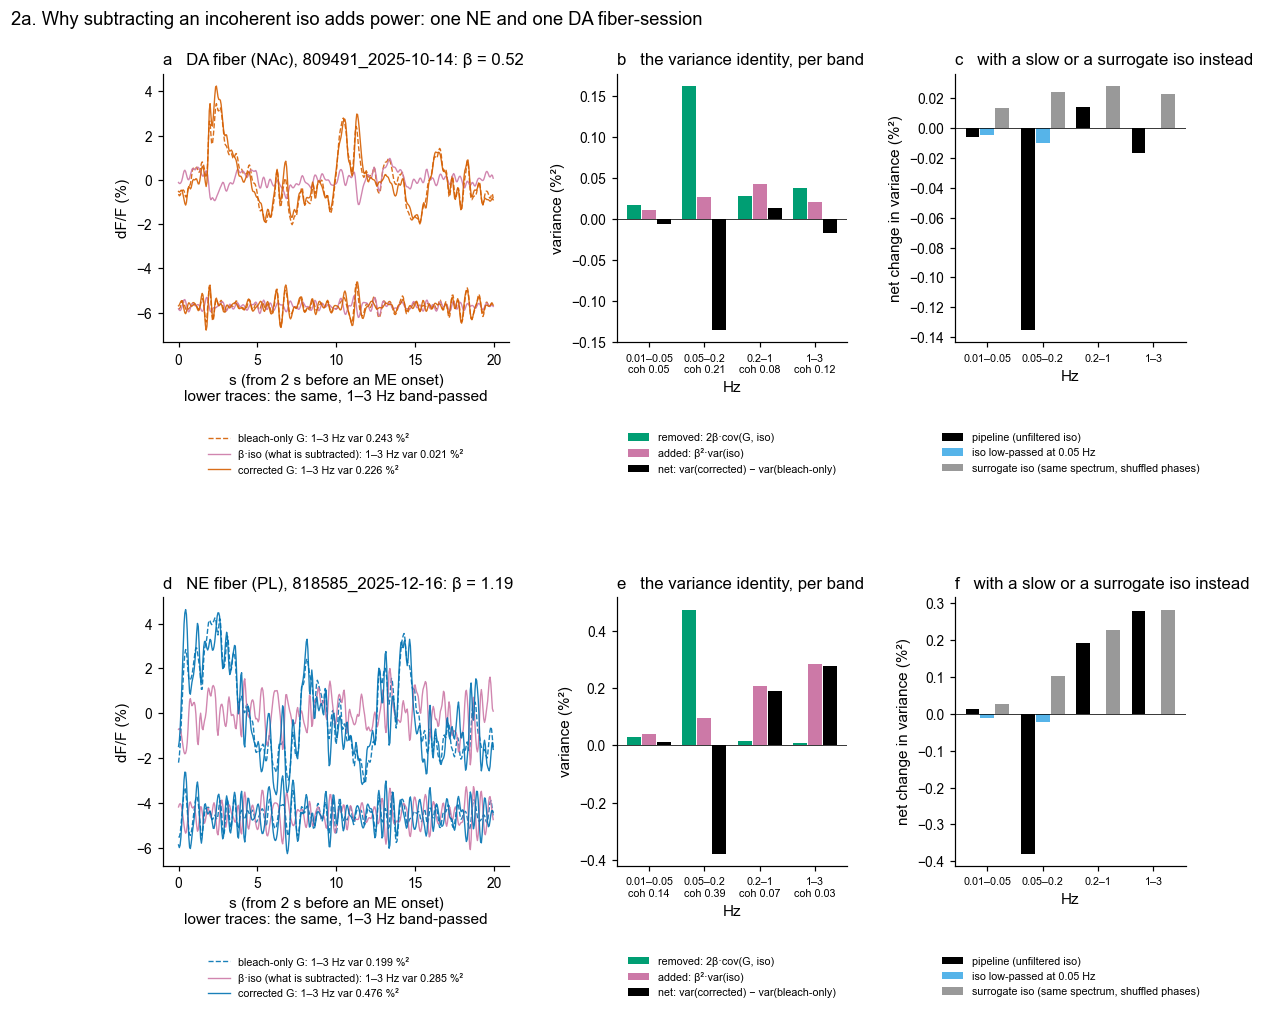

In [12]:
fig = plt.figure(figsize=(12, 9.6))
gs = GridSpec(2, 3, figure=fig, wspace=0.4, hspace=0.95, top=0.92, bottom=0.17, width_ratios=[1.5, 1, 1])
LEGEND_BELOW = dict(loc="upper center", bbox_to_anchor=(0.5, -0.3), frameon=False)
for k, role in enumerate(ROLES):
    ses = examples[role]
    p = next(q for q in pairs if q["session"] == ses)
    beta = p["beta"][(role, "G")]
    g3 = p["x"][(role, "G", "bleach")].astype(float)
    iso3 = fu.noise_lowpass(p["x"][(role, "Iso", "bleach_unfiltered")].astype(float), FS)
    mc = p["x"][(role, "G", "corrected")].astype(float)
    sub = beta * (iso3 - iso3.mean())
    # (i) a 20 s excerpt starting at the median ME onset, raw and in the example band
    on = p["me_onsets"][len(p["me_onsets"]) // 2]
    i0 = int((on - p["t0"]) * FS) - int(2 * FS)
    sl = slice(i0, i0 + int(EXAMPLE_SPAN_S * FS))
    tt = np.arange(sl.stop - sl.start) / FS
    ax = fig.add_subplot(gs[k, 0])
    for name, y, color, ls in (("bleach-only G", g3, SENSOR_COLOR[role], "--"), ("β·iso (what is subtracted)", sub, CH_COLOR["Iso"], "-"),
                               ("corrected G", mc, SENSOR_COLOR[role], "-")):
        yb = bandpass(y, EXAMPLE_BAND)
        ax.plot(tt, 100 * y[sl] - 100 * y[sl].mean(), color=color, ls=ls, lw=0.9, alpha=0.9,
                label=f"{name}: {EXAMPLE_BAND} Hz var {1e4 * yb.var():.3f} %²")
        ax.plot(tt, 100 * yb[sl] - 2.5 * 100 * np.nanstd(g3), color=color, ls=ls, lw=0.9, alpha=0.9)
    ax.set_xlabel(f"s (from 2 s before an ME onset)\nlower traces: the same, {EXAMPLE_BAND} Hz band-passed")
    ax.set_ylabel("dF/F (%)")
    ax.set_title(f"{'ad'[k]}   {ROLE_LABEL[role]}, {ses}: β = {beta:.2f}", loc="left")
    ax.legend(fontsize=7, **LEGEND_BELOW)
    style_ax(ax)
    # (ii) the three terms per band, pipeline
    ax = fig.add_subplot(gs[k, 1])
    tdf = terms[role]["pipeline (unfiltered iso)"]
    xs = np.arange(len(BANDS))
    for j, (col, color, label) in enumerate((("removed", OKABE_ITO["bluish_green"], "removed: 2β·cov(G, iso)"),
                                             ("added", CH_COLOR["Iso"], "added: β²·var(iso)"),
                                             ("net", "k", "net: var(corrected) − var(bleach-only)"))):
        ax.bar(xs + (j - 1) * 0.27, tdf[col], 0.25, color=color, label=label)
    cohs = [band_sess.set_index(["session", "role"]).loc[(ses, role), f"coh|{b}"] for b in BANDS]
    ax.axhline(0, color="k", lw=0.5)
    ax.set_xticks(xs)
    ax.set_xticklabels([f"{b}\ncoh {c:.2f}" for b, c in zip(BANDS, cohs)], fontsize=7)
    ax.set_xlabel("Hz")
    ax.set_ylabel("variance (%²)")
    ax.set_title(f"{'be'[k]}   the variance identity, per band", loc="left")
    ax.legend(fontsize=7, **LEGEND_BELOW)
    style_ax(ax)
    # (iii) net change under the three variants
    ax = fig.add_subplot(gs[k, 2])
    for j, (name, color) in enumerate(zip(terms[role], ("k", OKABE_ITO["sky_blue"], "0.6"))):
        ax.bar(xs + (j - 1) * 0.27, terms[role][name]["net"], 0.25, color=color, label=name)
    ax.axhline(0, color="k", lw=0.5)
    ax.set_xticks(xs)
    ax.set_xticklabels(list(BANDS), fontsize=7)
    ax.set_xlabel("Hz")
    ax.set_ylabel("net change in variance (%²)")
    ax.set_title(f"{'cf'[k]}   with a slow or a surrogate iso instead", loc="left")
    ax.legend(fontsize=7, **LEGEND_BELOW)
    style_ax(ax)
fig.suptitle("2a. Why subtracting an incoherent iso adds power: one NE and one DA fiber-session", x=0.01, ha="left")
save_fig(fig, "fip_18_2a_worked_example", fig_dir=FIG_DIR, save=SAVE_FIG)
plt.show()

### 2b. The pipeline's β step by step, per fiber-session

For each fiber-session, on the full bleach-only recording (what the pipeline fitted): the slope of
G on Iso within each band (both traces band-passed, least squares), and the pipeline's fit in three
steps. Least squares on the 0.05 Hz low-passed traces equals the slopes of the two bands below
0.05 Hz (< 0.01 and 0.01–0.05 Hz) averaged with weights equal to each band's share of the
low-passed Iso power. The pipeline then fits robustly (positive residuals lose weight from 2
robust SDs, negative ones from 4.685) and clips the slope at 0. The last step reproduces the β in
`quality_control.json`.

In the figure, one row per fiber-session, sorted by the pipeline's β: the pipeline's β (black bar),
its robust fit before the clip where that was negative (open circle), and the band slopes. To the
right, the correlation of band-passed G and Iso in each band, which says how well each slope is
determined, and the share of the low-passed Iso power below 0.01 Hz.

In [13]:
steps = pd.DataFrame([dict(subject=p["subject"], session=p["session"], role=role, **p["beta_steps"][role])
                      for p in pairs for role in ROLES])
check = np.abs(steps["pipeline"] - steps.merge(band_sess[["session", "role", "beta"]], on=["session", "role"])["beta"]).max()
print(f"pipeline's fit reproduced: max |β − β in quality_control.json| = {check:.1e}")
FIT_BANDS = list(fu.BETA_FIT_BANDS)
ALL_STEP_BANDS = FIT_BANDS + list(STEP_BANDS)
for role in ROLES:
    d = steps[steps["role"] == role]
    zero = d[d["pipeline"] == 0]
    pos = d[d["pipeline"] > 0]
    shares = d["iso_share|<0.01"]
    print(f"\n{ROLE_LABEL[role]} ({len(d)} fiber-sessions)")
    print(f"  share of the low-passed Iso power below 0.01 Hz: median {shares.median():.2f} (range {shares.min():.2f}–{shares.max():.2f})")
    print(f"  least squares on the low-passed traces vs the weighted band slopes: r = "
          f"{np.corrcoef(d['ols_lp'], (d[[f'iso_share|{b}' for b in FIT_BANDS]].to_numpy() * d[[f'beta|{b}' for b in FIT_BANDS]].to_numpy()).sum(1))[0, 1]:.3f}")
    print(f"  robust vs least squares: r = {np.corrcoef(d['rlm'], d['ols_lp'])[0, 1]:.2f}, median |difference| {np.median(np.abs(d['rlm'] - d['ols_lp'])):.2f}")
    print(f"  β = 0 (robust fit negative): {len(zero)}; of these, slope < 0.01 Hz negative in {(zero['beta|<0.01'] < 0).sum()}, "
          f"slope 0.01–0.05 Hz negative in {(zero['beta|0.01–0.05'] < 0).sum()}")
    print("  r of the pipeline's β (β > 0) with the slope in each band: "
          + ", ".join(f"{b} {np.corrcoef(pos['pipeline'], pos[f'beta|{b}'])[0, 1]:.2f}" for b in ALL_STEP_BANDS))
    print("  median band slope / median |band r|: "
          + ", ".join(f"{b} {d[f'beta|{b}'].median():.2f} / {d[f'r|{b}'].abs().median():.2f}" for b in ALL_STEP_BANDS))
steps.to_csv(os.path.join(fu.CACHE_ROOT, "fip_18", "beta_steps.csv"), index=False)

pipeline's fit reproduced: max |β − β in quality_control.json| = 1.4e-11

DA fiber (NAc) (85 fiber-sessions)
  share of the low-passed Iso power below 0.01 Hz: median 0.82 (range 0.56–1.00)
  least squares on the low-passed traces vs the weighted band slopes: r = 0.998
  robust vs least squares: r = 0.62, median |difference| 1.41
  β = 0 (robust fit negative): 41; of these, slope < 0.01 Hz negative in 38, slope 0.01–0.05 Hz negative in 15
  r of the pipeline's β (β > 0) with the slope in each band: <0.01 0.34, 0.01–0.05 0.08, 0.05–0.2 0.15, 0.2–1 -0.06, 1–3 -0.08
  median band slope / median |band r|: <0.01 -2.76 / 0.36, 0.01–0.05 0.84 / 0.16, 0.05–0.2 1.02 / 0.25, 0.2–1 -5.57 / 0.27, 1–3 -0.57 / 0.13

NE fiber (PL) (85 fiber-sessions)
  share of the low-passed Iso power below 0.01 Hz: median 0.82 (range 0.62–0.97)
  least squares on the low-passed traces vs the weighted band slopes: r = 0.997
  robust vs least squares: r = 0.90, median |difference| 0.09
  β = 0 (robust fit negative): 

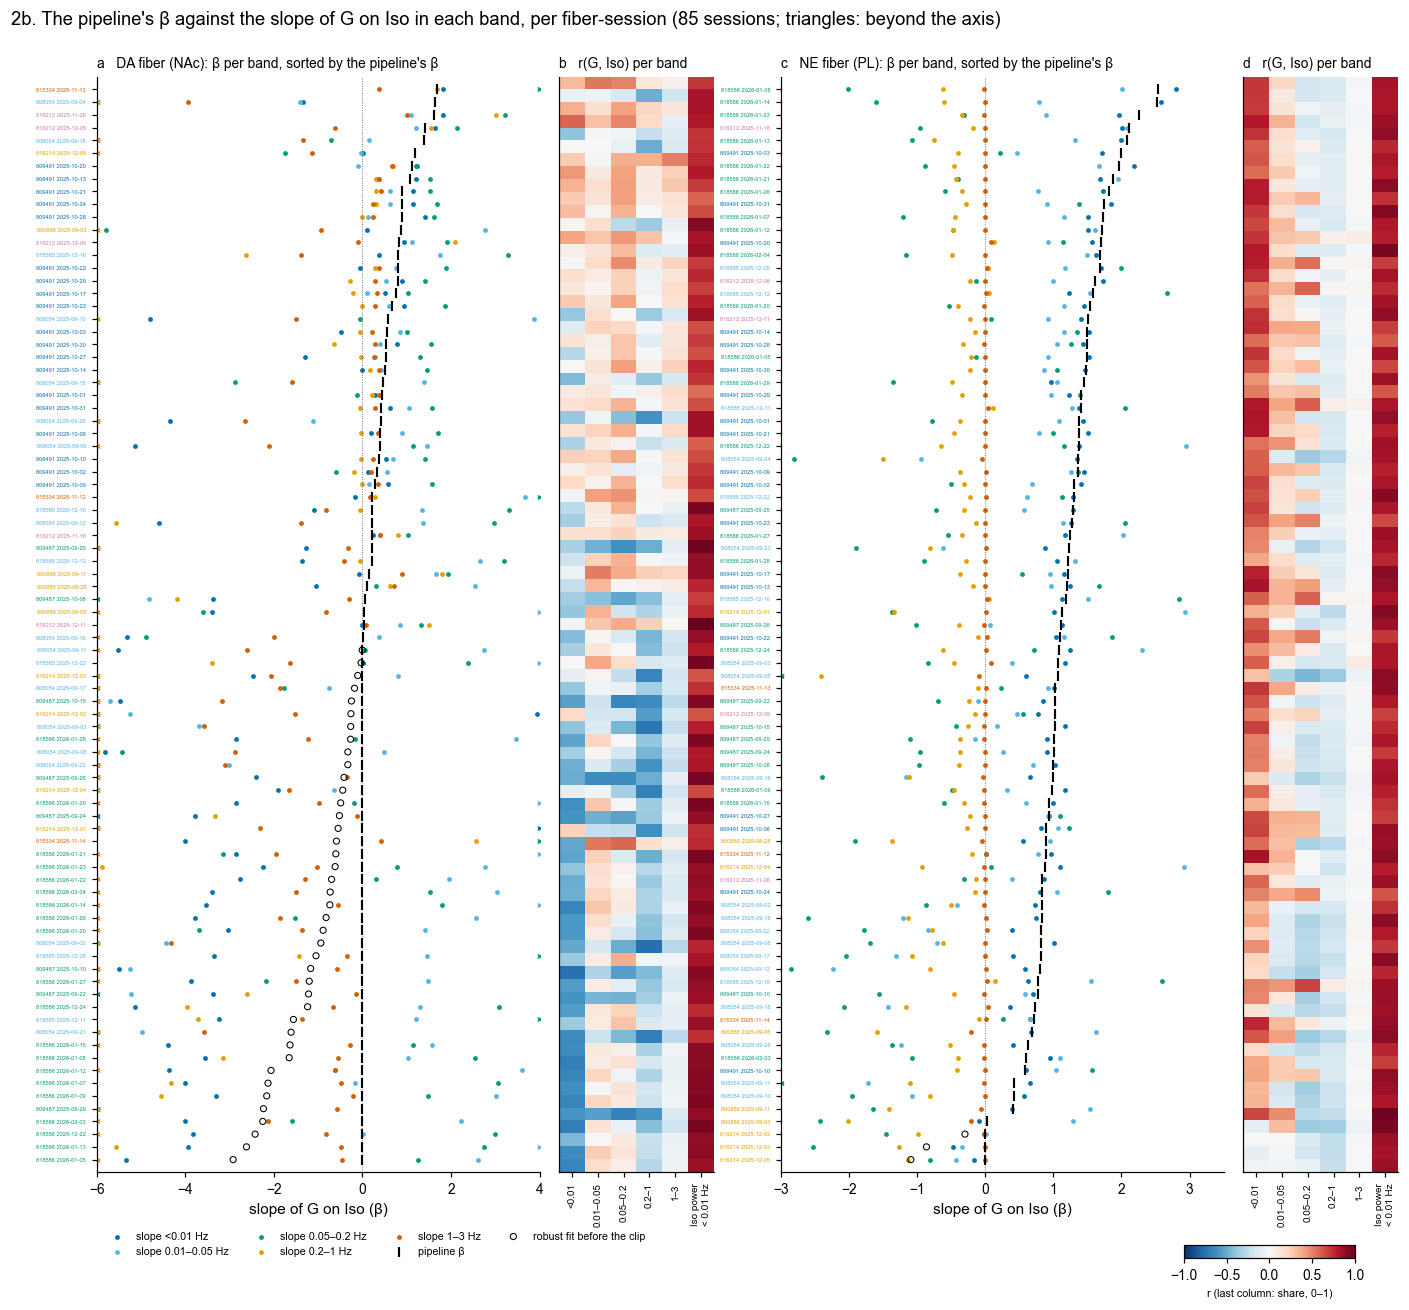

In [14]:
STEP_COLOR = {"<0.01": OKABE_ITO["blue"], "0.01–0.05": OKABE_ITO["sky_blue"], "0.05–0.2": OKABE_ITO["bluish_green"],
              "0.2–1": OKABE_ITO["orange"], "1–3": OKABE_ITO["vermillion"]}
XLIM = {"da": (-6, 4), "ne": (-3, 3.5)}
fig = plt.figure(figsize=(13, 12))
gs = fig.add_gridspec(1, 5, width_ratios=[4, 1.4, 0.25, 4, 1.4], wspace=0.08, left=0.07, right=0.98, top=0.93, bottom=0.1)
for k, role in enumerate(ROLES):
    d = steps[steps["role"] == role].sort_values(["pipeline", "rlm"]).reset_index(drop=True)
    y = np.arange(len(d))
    lo, hi = XLIM[role]
    ax = fig.add_subplot(gs[0, 3 * k])
    for b in ALL_STEP_BANDS:
        v = d[f"beta|{b}"].to_numpy()
        inside = (v >= lo) & (v <= hi)
        ax.scatter(v[inside], y[inside], s=10, color=STEP_COLOR[b], lw=0, label=f"slope {b} Hz", zorder=2)
        ax.scatter(np.full((v < lo).sum(), lo), y[v < lo], s=12, color=STEP_COLOR[b], marker="<", lw=0, zorder=2)
        ax.scatter(np.full((v > hi).sum(), hi), y[v > hi], s=12, color=STEP_COLOR[b], marker=">", lw=0, zorder=2)
    ax.scatter(d["pipeline"], y, s=40, color="k", marker="|", lw=1.4, label="pipeline β", zorder=3)
    neg = d["rlm"] < 0
    ax.scatter(d.loc[neg, "rlm"].clip(lo, hi), y[neg], s=16, facecolor="none", edgecolor="k", lw=0.7,
               label="robust fit before the clip", zorder=3)
    ax.axvline(0, color=PALETTE["neutral"], lw=0.6, ls=":")
    ax.set_xlim(lo, hi)
    ax.set_ylim(-1, len(d))
    ax.set_yticks(y)
    ax.set_yticklabels([f"{s} {ses.split('_', 1)[1]}" for s, ses in zip(d["subject"], d["session"])], fontsize=3.8)
    for t, s in zip(ax.get_yticklabels(), d["subject"]):
        t.set_color(STYLES[s][0])
    ax.set_xlabel("slope of G on Iso (β)")
    ax.set_title(f"{'ac'[k]}   {ROLE_LABEL[role]}: β per band, sorted by the pipeline's β", loc="left", fontsize=9)
    style_ax(ax)
    if k == 0:
        ax.legend(fontsize=7, ncol=4, loc="upper left", bbox_to_anchor=(0, -0.045), frameon=False)
    ax = fig.add_subplot(gs[0, 3 * k + 1])
    cols = [f"r|{b}" for b in ALL_STEP_BANDS] + ["iso_share|<0.01"]
    im = ax.imshow(d[cols].to_numpy(), aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1, origin="lower",
                   extent=(-0.5, len(cols) - 0.5, -1, len(d)))
    ax.set_xticks(range(len(cols)))
    ax.set_xticklabels([b for b in ALL_STEP_BANDS] + ["Iso power\n< 0.01 Hz"], rotation=90, fontsize=6.5)
    ax.set_yticks([])
    ax.set_title(f"{'bd'[k]}   r(G, Iso) per band", loc="left", fontsize=9)
cax = fig.add_axes([0.83, 0.035, 0.12, 0.01])
fig.colorbar(im, cax=cax, orientation="horizontal").set_label("r (last column: share, 0–1)", fontsize=7)
fig.suptitle(f"2b. The pipeline's β against the slope of G on Iso in each band, per fiber-session ({len(pairs)} sessions; "
             "triangles: beyond the axis)", x=0.01, ha="left")
save_fig(fig, "fip_18_2b_beta_steps", fig_dir=FIG_DIR, save=SAVE_FIG)
plt.show()

## 3. Iso and the red channel against motion energy

If movement shows up in the optics, it shows up in Iso (and in the sensor-free red channel of
the PL fiber), which carry no sensor signal at the go cue or outcome. Per fiber-session: the
normalised cross-correlation of ME with Iso, R, bleach-only G and corrected G (all with the 3 Hz
filter; positive lag = the signal follows ME), and each averaged around ME onsets in dF/F %,
together with β·Iso — what the correction subtracts at those moments. The corrected and bleach-only
curves differ by exactly that.

What to look for: how large the Iso and R responses at ME onsets are next to the sensor's; whether
Iso's ME cross-correlation is at the level of the sensor's or of noise; and whether β·Iso at ME
onsets is a deflection (artifact the correction removes) or only noise (which it adds).

In [15]:
XC_SIGNALS = (("Iso", "bleach"), ("R", "bleach"), ("G", "bleach"), ("G", "corrected"))
xc = {(role, sig): [] for role in ROLES for sig in XC_SIGNALS}
eta = {(role, sig): [] for role in ROLES for sig in XC_SIGNALS + (("beta_iso", ""),)}
resp_rows = []
for p in pairs:
    me = p["z"]["me"]
    on = p["me_onsets"]
    for role in ROLES:
        r = dict(subject=p["subject"], session=p["session"], role=role)
        for ch, stage in XC_SIGNALS:
            y = p["x"][(role, ch, stage)].astype(float)
            lags, c = su.norm_xcorr(y, me, FS, XCORR_MAXLAG)
            xc[(role, (ch, stage))].append((p["subject"], c))
            seg = su.peri_event_grid(100 * y, p["t0"], FS, on, ETA_LAGS)
            pre = np.nanmean(seg[:, (ETA_LAGS >= PRE_WIN[0]) & (ETA_LAGS < PRE_WIN[1])], 1)
            post = np.nanmean(seg[:, (ETA_LAGS >= RESP_WIN[0]) & (ETA_LAGS < RESP_WIN[1])], 1)
            eta[(role, (ch, stage))].append((p["subject"], np.nanmean(seg - pre[:, None], 0)))
            r[f"resp|{ch} {stage}"] = np.nanmean(post - pre)
            r[f"xcpeak|{ch} {stage}"] = c[np.nanargmax(np.abs(c))]
        iso = p["x"][(role, "Iso", "bleach")].astype(float)
        sub = p["beta"][(role, "G")] * (iso - iso.mean())
        seg = su.peri_event_grid(100 * sub, p["t0"], FS, on, ETA_LAGS)
        pre = np.nanmean(seg[:, (ETA_LAGS >= PRE_WIN[0]) & (ETA_LAGS < PRE_WIN[1])], 1)
        eta[(role, ("beta_iso", ""))].append((p["subject"], np.nanmean(seg - pre[:, None], 0)))
        resp_rows.append(r)
XC_LAGS = lags
resp_sess = pd.DataFrame(resp_rows)
resp_animal = {role: st.animal_means(resp_sess[resp_sess["role"] == role], [c for c in resp_sess if "|" in c], by_session=False) for role in ROLES}
for role in ROLES:
    print(f"── {ROLE_LABEL[role]}: response at ME onsets (% dF/F, 0–1 s minus −1 to −0.2 s) and peak r with ME, mean over animals, Wilcoxon vs 0")
    rows = []
    for c in [c for c in resp_animal[role] if c.startswith("resp") or c.startswith("xcpeak")]:
        m, pv, n = st.wilcoxon_animals(resp_animal[role][c])
        rows.append(dict(measure=c, mean=m, p=pv, n=n))
    print(pd.DataFrame(rows).to_string(index=False, float_format=lambda v: f"{v:.3g}"))

── DA fiber (NAc): response at ME onsets (% dF/F, 0–1 s minus −1 to −0.2 s) and peak r with ME, mean over animals, Wilcoxon vs 0
           measure      mean       p  n
   resp|Iso bleach     0.149   0.301  9
 xcpeak|Iso bleach     0.195  0.0117  9
     resp|R bleach -0.000664       1  9
   xcpeak|R bleach    0.0633   0.301  9
     resp|G bleach     0.624    0.57  9
   xcpeak|G bleach     0.335 0.00391  9
  resp|G corrected     0.519   0.734  9
xcpeak|G corrected     0.328 0.00391  9
── NE fiber (PL): response at ME onsets (% dF/F, 0–1 s minus −1 to −0.2 s) and peak r with ME, mean over animals, Wilcoxon vs 0
           measure    mean       p  n
   resp|Iso bleach -0.0532 0.00391  9
 xcpeak|Iso bleach -0.0164    0.57  9
     resp|R bleach  0.0417  0.0391  9
   xcpeak|R bleach  0.0791  0.0742  9
     resp|G bleach     1.1 0.00391  9
   xcpeak|G bleach   0.697 0.00391  9
  resp|G corrected    1.15 0.00391  9
xcpeak|G corrected   0.637 0.00391  9


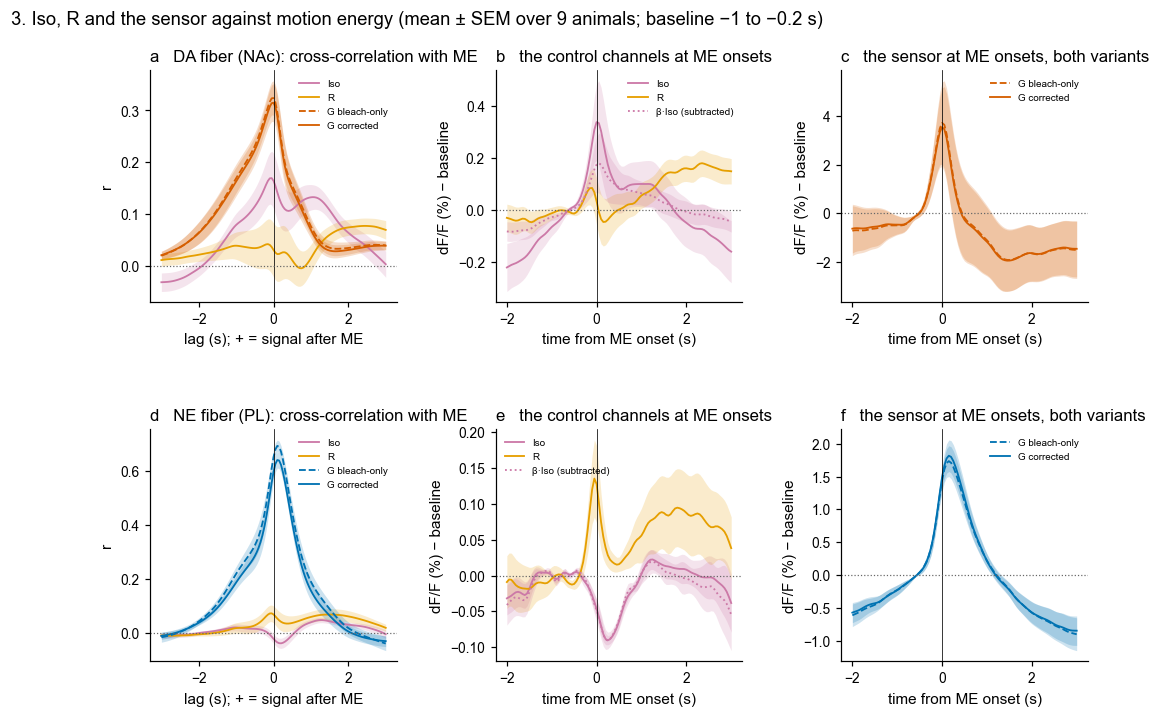

In [16]:
def animal_traces(entries):
    subj, tr = zip(*entries)
    return st.group_means(tr, subj)[1]


SIG_STYLE = {("Iso", "bleach"): (CH_COLOR["Iso"], "-", "Iso"), ("R", "bleach"): (CH_COLOR["R"], "-", "R"),
             ("G", "bleach"): (None, "--", "G bleach-only"), ("G", "corrected"): (None, "-", "G corrected"),
             ("beta_iso", ""): (CH_COLOR["Iso"], ":", "β·Iso (subtracted)")}
fig = plt.figure(figsize=(11, 6.8))
gs = GridSpec(2, 3, figure=fig, wspace=0.4, hspace=0.55, top=0.9)
for k, role in enumerate(ROLES):
    ax = fig.add_subplot(gs[k, 0])
    for sig in XC_SIGNALS:
        color, ls, label = SIG_STYLE[sig]
        pu.plot_mean_sem(ax, XC_LAGS, animal_traces(xc[(role, sig)]), color or SENSOR_COLOR[role], label, ls=ls, lw=1.2)
    ax.axvline(0, color="k", lw=0.5)
    ax.axhline(0, color=PALETTE["neutral"], lw=0.8, ls=":")
    ax.set_xlabel("lag (s); + = signal after ME")
    ax.set_ylabel("r")
    ax.set_title(f"{'ad'[k]}   {ROLE_LABEL[role]}: cross-correlation with ME", loc="left")
    ax.legend(fontsize=6.5)
    style_ax(ax)

    ax = fig.add_subplot(gs[k, 1])
    for sig in (("Iso", "bleach"), ("R", "bleach"), ("beta_iso", "")):
        color, ls, label = SIG_STYLE[sig]
        pu.plot_mean_sem(ax, ETA_LAGS, animal_traces(eta[(role, sig)]), color, label, ls=ls, lw=1.2)
    ax.axvline(0, color="k", lw=0.5)
    ax.axhline(0, color=PALETTE["neutral"], lw=0.8, ls=":")
    ax.set_xlabel("time from ME onset (s)")
    ax.set_ylabel("dF/F (%) − baseline")
    ax.set_title(f"{'be'[k]}   the control channels at ME onsets", loc="left")
    ax.legend(fontsize=6.5)
    style_ax(ax)

    ax = fig.add_subplot(gs[k, 2])
    for sig in (("G", "bleach"), ("G", "corrected")):
        color, ls, label = SIG_STYLE[sig]
        pu.plot_mean_sem(ax, ETA_LAGS, animal_traces(eta[(role, sig)]), SENSOR_COLOR[role], label, ls=ls, lw=1.2)
    ax.axvline(0, color="k", lw=0.5)
    ax.axhline(0, color=PALETTE["neutral"], lw=0.8, ls=":")
    ax.set_xlabel("time from ME onset (s)")
    ax.set_ylabel("dF/F (%) − baseline")
    ax.set_title(f"{'cf'[k]}   the sensor at ME onsets, both variants", loc="left")
    ax.legend(fontsize=6.5)
    style_ax(ax)
fig.suptitle(f"3. Iso, R and the sensor against motion energy (mean ± SEM over {N_ANIMALS} animals; baseline −1 to −0.2 s)", x=0.01, ha="left")
save_fig(fig, "fip_18_3_iso_vs_me", fig_dir=FIG_DIR, save=SAVE_FIG)
plt.show()

## 4. Fiber events in iso, and the step after task events

**Fiber events.** A brief, huge excursion on every channel of a fiber is a disturbance of the
fiber or patch cord, not activity. Iso shows it without any sensor signal in the way. Per iso trace
(bleach-only, unfiltered), the peak of |z| with a robust z (median and MAD), and the longest run
above 10 robust SD. The pipeline's QC has no such check. The proposed rule — mask ± 30 s around any
excursion above 30 robust SD — is applied here only to count what it would remove.

**The post-event step.** The video-latents work saw a ~0.2 % step about 3 s after every task event
in iso (and ACh). Iso, G and R of both fibers are averaged at go cues and at outcomes (rewarded /
unrewarded), out to 8 s, baseline −1 to 0 s, to see whether the step is in these sessions and in
which channels.

In [17]:
def robust_z(x):
    med = np.nanmedian(x)
    mad = 1.4826 * np.nanmedian(np.abs(x - med))
    return (x - med) / mad


ev_rows = []
for p in pairs:
    n = len(p["da"])
    for role in ROLES:
        z = robust_z(p["x"][(role, "Iso", "bleach_unfiltered")].astype(float))
        above = np.abs(z) > EVENT_SD
        runs10 = su.contiguous_runs(np.abs(z) > 10)
        masked = np.zeros(n, bool)
        for a, b in su.contiguous_runs(above):
            masked[max(0, a - int(EVENT_MASK_S * FS)):b + 1 + int(EVENT_MASK_S * FS)] = True
        ev_rows.append(dict(subject=p["subject"], session=p["session"], role=role, fiber=p["fiber"][role],
                            peak_sd=np.nanmax(np.abs(z)), t_peak=p["t0"] + np.nanargmax(np.abs(z)) / FS,
                            longest_run_10sd_s=max([(b - a + 1) / FS for a, b in runs10], default=0.0),
                            n_events=len(su.contiguous_runs(above)), masked_frac=masked.mean()))
events = pd.DataFrame(ev_rows)
flagged = events[events["peak_sd"] > EVENT_SD].sort_values("peak_sd", ascending=False)
print(f"peak |z| of iso per fiber-session: median {events['peak_sd'].median():.1f}, 99th percentile {events['peak_sd'].quantile(0.99):.1f}")
print(f"{len(flagged)} of {len(events)} fiber-sessions ({flagged['session'].nunique()} sessions) exceed {EVENT_SD:.0f} robust SD; "
      f"the ± {EVENT_MASK_S:.0f} s rule would remove a median {100 * flagged['masked_frac'].median():.1f}% of those sessions")
print(flagged[["subject", "session", "role", "fiber", "peak_sd", "t_peak", "longest_run_10sd_s", "n_events", "masked_frac"]]
      .to_string(index=False, float_format=lambda v: f"{v:.1f}"))
root0 = list(asset_roots.values())[0]
cur0 = pd.read_csv(os.path.join(root0, sorted(f for f in os.listdir(root0) if f.startswith("df_curation"))[0]))
print("\ncuration columns the flagged sessions could be crossed with:", list(cur0.columns))

peak |z| of iso per fiber-session: median 5.3, 99th percentile 16.1
1 of 170 fiber-sessions (1 sessions) exceed 30 robust SD; the ± 30 s rule would remove a median 2.5% of those sessions
subject           session role  fiber  peak_sd  t_peak  longest_run_10sd_s  n_events  masked_frac
 809491 809491_2025-10-20   da      2    126.1  2994.8                65.1         1          0.0

curation columns the flagged sessions could be crossed with: ['subject', 'session_id', 'fiber', 'target', 'keep', 'dropped_by', 'drop_reason', 'snr_envelope', 'snr', 'skewness', 'kurtosis']


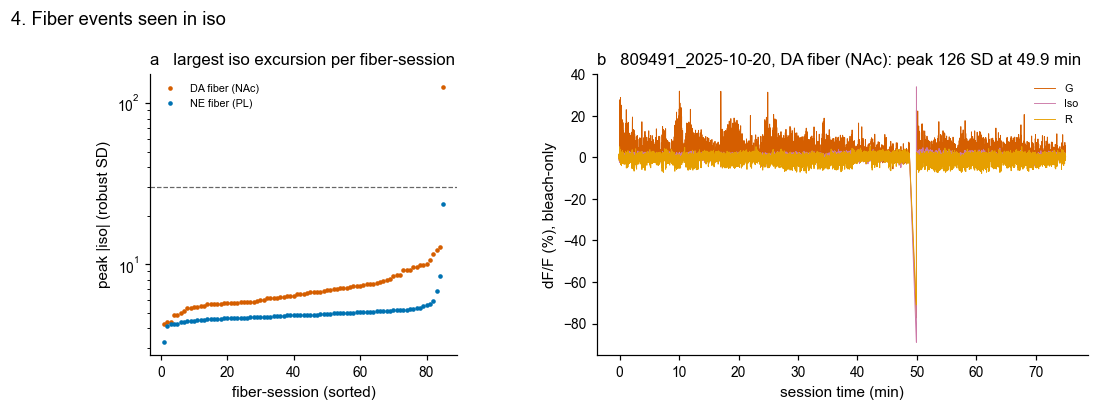

In [18]:
fig = plt.figure(figsize=(11, 3.6))
gs = GridSpec(1, 2, figure=fig, wspace=0.35, top=0.82, width_ratios=[1, 1.6])
ax = fig.add_subplot(gs[0])
for role in ROLES:
    v = np.sort(events.loc[events["role"] == role, "peak_sd"].to_numpy())
    ax.plot(np.arange(1, len(v) + 1), v, ".", ms=4, color=SENSOR_COLOR[role], label=ROLE_LABEL[role])
ax.axhline(EVENT_SD, color=PALETTE["neutral"], lw=0.8, ls="--")
ax.set_yscale("log")
ax.set_xlabel("fiber-session (sorted)")
ax.set_ylabel("peak |iso| (robust SD)")
ax.set_title("a   largest iso excursion per fiber-session", loc="left")
ax.legend(fontsize=7)
style_ax(ax)

ax = fig.add_subplot(gs[1])
if len(flagged):
    ex = flagged.iloc[0]
    p = next(q for q in pairs if q["session"] == ex["session"])
    tt = p["t0"] + np.arange(len(p["da"])) / FS
    for ch, color in (("G", SENSOR_COLOR[ex["role"]]), ("Iso", CH_COLOR["Iso"]), ("R", CH_COLOR["R"])):
        ax.plot(tt / 60, 100 * p["x"][(ex["role"], ch, "bleach_unfiltered")], color=color, lw=0.6, label=ch)
    ax.set_xlabel("session time (min)")
    ax.set_ylabel("dF/F (%), bleach-only")
    ax.set_title(f"b   {ex['session']}, {ROLE_LABEL[ex['role']]}: peak {ex['peak_sd']:.0f} SD at {ex['t_peak'] / 60:.1f} min", loc="left")
    ax.legend(fontsize=7)
else:
    ax.text(0.5, 0.5, f"no iso excursion above {EVENT_SD:.0f} robust SD", ha="center", transform=ax.transAxes)
style_ax(ax)
fig.suptitle("4. Fiber events seen in iso", x=0.01, ha="left")
save_fig(fig, "fip_18_4_fiber_events", fig_dir=FIG_DIR, save=SAVE_FIG)
plt.show()

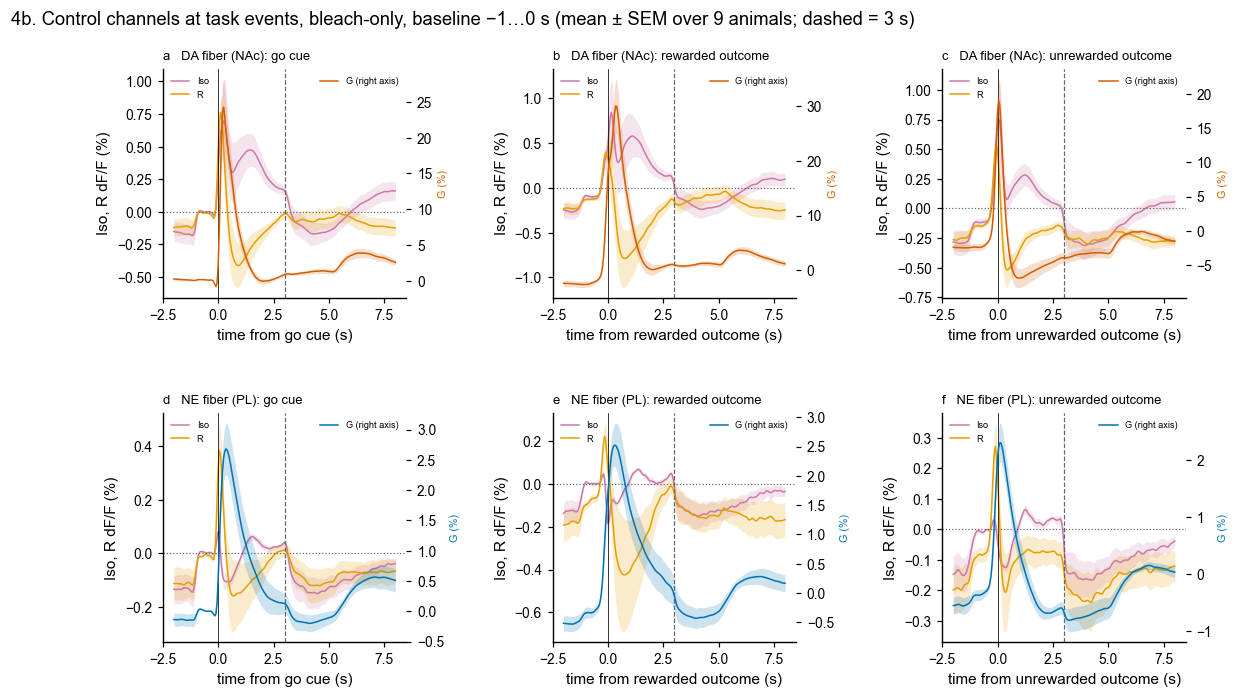

In [19]:
def event_times(p, kind):
    tr = p["trials"]
    if kind == "go cue":
        return tr["goCue_start_time_in_session"].dropna().to_numpy()
    resp = tr["animal_response"].isin([0, 1])
    rewarded = tr["earned_reward"].astype(float) > 0
    sel = resp & (rewarded if kind == "rewarded outcome" else ~rewarded)
    return tr.loc[sel, "reward_outcome_time_in_session"].dropna().to_numpy()


STEP_KINDS = ("go cue", "rewarded outcome", "unrewarded outcome")
step = {(role, ch, kind): [] for role in ROLES for ch in CHANNELS for kind in STEP_KINDS}
base = (STEP_LAGS >= STEP_BASE[0]) & (STEP_LAGS < STEP_BASE[1])
for p in pairs:
    for kind in STEP_KINDS:
        times = event_times(p, kind)
        for role in ROLES:
            for ch in CHANNELS:
                seg = su.peri_event_grid(100 * p["x"][(role, ch, "bleach")].astype(float), p["t0"], FS, times, STEP_LAGS)
                seg = seg - np.nanmean(seg[:, base], 1, keepdims=True)
                step[(role, ch, kind)].append((p["subject"], np.nanmean(seg, 0)))

fig = plt.figure(figsize=(12, 6.6))
gs = GridSpec(2, 3, figure=fig, wspace=0.6, hspace=0.5, top=0.9)
for k, role in enumerate(ROLES):
    for j, kind in enumerate(STEP_KINDS):
        ax = fig.add_subplot(gs[k, j])
        for ch, color in (("G", SENSOR_COLOR[role]), ("Iso", CH_COLOR["Iso"]), ("R", CH_COLOR["R"])):
            m = animal_traces(step[(role, ch, kind)])
            if ch == "G":
                ax2 = ax.twinx()
                pu.plot_mean_sem(ax2, STEP_LAGS, m, color, f"{ch} (right axis)", lw=1.0)
                ax2.set_ylabel("G (%)", color=color, fontsize=7)
                ax2.legend(fontsize=6, loc="upper right")
            else:
                pu.plot_mean_sem(ax, STEP_LAGS, m, color, ch, lw=1.0)
        ax.axvline(0, color="k", lw=0.5)
        ax.axvline(3, color=PALETTE["neutral"], lw=0.8, ls="--")
        ax.axhline(0, color=PALETTE["neutral"], lw=0.8, ls=":")
        ax.set_xlabel(f"time from {kind} (s)")
        ax.set_ylabel("Iso, R dF/F (%)")
        ax.set_title(f"{'abcdef'[k * 3 + j]}   {ROLE_LABEL[role]}: {kind}", loc="left", fontsize=8.5)
        ax.legend(fontsize=6, loc="upper left")
        style_ax(ax)
fig.suptitle(f"4b. Control channels at task events, bleach-only, baseline −1…0 s (mean ± SEM over {N_ANIMALS} animals; dashed = 3 s)", x=0.01, ha="left")
save_fig(fig, "fip_18_4b_post_event_step", fig_dir=FIG_DIR, save=SAVE_FIG)
plt.show()

## 5. Downstream: corrected vs bleach-only

The measures that `fip_10` §1–2 and `fip_12` §1 rest on, computed on both variants of each sensor,
z-scored per session as there: the peak cross-correlation of DA and NE with ME and its lag; the
response at ME onsets (0–1 s minus −1 to −0.2 s, in z); and the DA–NE cross-correlation peak.
Per animal, then the paired difference (bleach-only − corrected) with a Wilcoxon test over animals.
`fip_13`'s regressions are not rerun here.

In [20]:
def coupling_row(p, x):
    # §5's measures for one session; x[(role, "G", stage)] holds the two variants of each sensor
    me = p["z"]["me"]
    on = p["me_onsets"]
    r = dict(subject=p["subject"], session=p["session"])
    zs = {(role, stage): su.zscore(x[(role, "G", stage)].astype(float)) for role in ROLES for stage in STAGES}
    for stage in STAGES:
        for role in ROLES:
            lags, c = su.norm_xcorr(zs[(role, stage)], me, FS, XCORR_MAXLAG)
            k = int(np.nanargmax(np.abs(c)))
            r[f"{role} × ME peak r|{stage}"] = c[k]
            r[f"{role} × ME lag s|{stage}"] = lags[k]
            seg = su.peri_event_grid(zs[(role, stage)], p["t0"], FS, on, ETA_LAGS)
            pre = np.nanmean(seg[:, (ETA_LAGS >= PRE_WIN[0]) & (ETA_LAGS < PRE_WIN[1])], 1)
            post = np.nanmean(seg[:, (ETA_LAGS >= RESP_WIN[0]) & (ETA_LAGS < RESP_WIN[1])], 1)
            r[f"{role} at ME onsets z|{stage}"] = np.nanmean(post - pre)
        lags, c = su.norm_xcorr(zs[("ne", stage)], zs[("da", stage)], FS, XCORR_MAXLAG)
        k = int(np.nanargmax(np.abs(c)))
        r[f"DA × NE peak r|{stage}"] = c[k]
        r[f"DA × NE lag s|{stage}"] = lags[k]
    return r


def coupling_table(down_animal):
    # per measure: mean over animals of each variant, and bleach-only − corrected with a Wilcoxon over animals
    out = []
    for m in MEASURES:
        d = down_animal[f"{m}|bleach"] - down_animal[f"{m}|corrected"]
        mean_d, pv, n = st.wilcoxon_animals(d)
        out.append(dict(measure=m, corrected=down_animal[f"{m}|corrected"].mean(), bleach_only=down_animal[f"{m}|bleach"].mean(),
                        difference=mean_d, p=pv, n_animals=n, animals_up=int((d > 0).sum())))
    return pd.DataFrame(out)


down_sess = pd.DataFrame([coupling_row(p, p["x"]) for p in pairs])
MEASURES = sorted({c.split("|")[0] for c in down_sess if "|" in c}, key=lambda s: [c for c in down_sess].index(f"{s}|bleach"))
down_animal = st.animal_means(down_sess, [c for c in down_sess if "|" in c], by_session=False)
down_table = coupling_table(down_animal)
print("mean over animals; difference = bleach-only − corrected, Wilcoxon over animals")
print(down_table.to_string(index=False, float_format=lambda v: f"{v:.3g}"))

mean over animals; difference = bleach-only − corrected, Wilcoxon over animals
          measure  corrected  bleach_only  difference       p  n_animals  animals_up
   da × ME peak r      0.328        0.335     0.00691  0.0929          9           7
    da × ME lag s    -0.0688      -0.0582      0.0106   0.593          9           2
da at ME onsets z     0.0728       0.0778     0.00495   0.327          9           6
   ne × ME peak r      0.637        0.697      0.0604 0.00781          9           8
    ne × ME lag s      0.176        0.102     -0.0734  0.0431          9           0
ne at ME onsets z      0.635        0.664      0.0297   0.164          9           6
   DA × NE peak r      0.267        0.312      0.0449 0.00391          9           9
    DA × NE lag s     0.0652         0.04     -0.0252   0.116          9           2


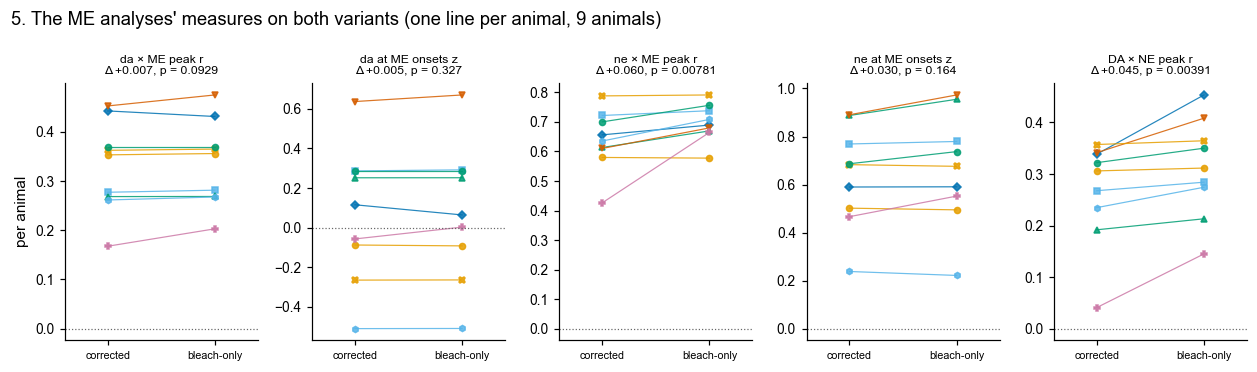

In [21]:
show = [m for m in MEASURES if "lag" not in m]
fig, axes = plt.subplots(1, len(show), figsize=(2.3 * len(show), 3.4))
for ax, m in zip(axes, show):
    for s in down_animal.index:
        y = [down_animal.loc[s, f"{m}|corrected"], down_animal.loc[s, f"{m}|bleach"]]
        ax.plot([0, 1], y, "-", color=STYLES[s][0], marker=STYLES[s][1], ms=4, lw=0.8, alpha=0.85)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["corrected", "bleach-only"], fontsize=7)
    ax.set_xlim(-0.4, 1.4)
    ax.axhline(0, color=PALETTE["neutral"], lw=0.8, ls=":")
    row = down_table.set_index("measure").loc[m]
    ax.set_title(f"{m}\nΔ {row['difference']:+.3f}, p {st.fmt_p(row['p'])}", fontsize=8)
    style_ax(ax)
axes[0].set_ylabel("per animal")
fig.suptitle(f"5. The ME analyses' measures on both variants (one line per animal, {N_ANIMALS} animals)", x=0.01, ha="left")
fig.tight_layout()
save_fig(fig, "fip_18_5_downstream", fig_dir=FIG_DIR, save=SAVE_FIG)
plt.show()

## 6. The `bright-v2` F0 fit

`aind-fip-dff` PR [#91](https://github.com/AllenNeuralDynamics/aind-fip-dff/pull/91) (2026-11-03,
in the commit that processed these NWBs) added a second F0 fit, `bright-v2`, and made it the
default; the curated traces still come from `bright`. The NWBs hold both. `bright-v2` fits a sum of
exponentials (additive, where `bright`'s terms multiply), with L-BFGS-B in place of Nelder–Mead,
bounded amplitudes, a stricter test for the third exponential, and a different robust fit: a
symmetric Tukey loss (c = 4) on a fixed scale equal to the trace's fast noise (MAD around a 1.55 s
running median), approached over 6 steps, where `bright` reweights with Tukey c = 3 on the MAD of
the negative residuals and down-weights upward transients by the residuals' skewness. dF/F = F / F0
− 1 in both, and the motion correction is the same code (`dff-bright-v2_mc-iso-IRLS`).

The question is whether §2's finding — on the NE fiber, subtracting β·iso adds power at 0.2–3 Hz —
depends on the F0 method. F0 is slow, so it can reach the fast bands only through β, which is
fitted below 0.05 Hz where the two F0 fits differ, and through the scale of dF/F (F / F0). Per
fiber-session: β and noise inflation from each method's QC; how alike the two bleach-only traces
are in each band (correlation of the band-passed traces, and their power ratio); the §2 power ratio
corrected / bleach-only by band for `bright-v2`; and §5's coupling measures on the `bright-v2`
variants. The pre-GoCue dF/F that PR #91 used to choose `bright-v2` is listed from the QC.

In [22]:
V2_STAGES = ("dff-bright-v2", "dff-bright-v2_mc-iso-IRLS")
rep_v2 = []
for p in pairs:
    row = rows_by_session[p["session"]]
    s3 = nwb_loc.loc[p["session"], "s3_location"]
    raw = fu.load_nwb_stages(s3, sorted(set(p["fiber"].values())), ("G", "Iso"), V2_STAGES, cache_dir=NWB_CACHE)
    qc2 = fu.load_pipeline_qc(s3, method="bright-v2", cache_dir=NWB_CACHE)
    t = raw["t"] + fu.session_time_offset(row.path)
    grid = p["t0"] + np.arange(len(p["da"])) / FS
    p["x2"], p["beta2"] = {}, {}
    p["qc2"] = qc2[qc2["fiber"].isin(p["fiber"].values())].assign(
        role=lambda d: d["fiber"].map({v: k for k, v in p["fiber"].items()}))
    for role, f in p["fiber"].items():
        for ch in ("G", "Iso"):
            b = raw[(f, ch, V2_STAGES[0])]
            for stage, y in {"bleach_unfiltered": b, "bleach": fu.noise_lowpass(np.nan_to_num(b), FS),
                             "corrected": raw[(f, ch, V2_STAGES[1])]}.items():
                ok = np.isfinite(y)
                p["x2"][(role, ch, stage)] = np.interp(grid, t[ok], y[ok]).astype(np.float32)
        p["beta2"][role] = float(qc2.set_index(["fiber", "channel"]).loc[(f, "G"), "beta"])
    # same check as §0: the corrected NE trace from the bleach-only stages and the QC's β
    f = p["fiber"]["ne"]
    g, iso = raw[(f, "G", V2_STAGES[0])], raw[(f, "Iso", V2_STAGES[0])]
    rep_v2.append(np.nanmax(np.abs(fu.noise_lowpass(g - p["beta2"]["ne"] * (iso - np.nanmean(iso)), FS) - raw[(f, "G", V2_STAGES[1])])))
print(f"check — bright-v2 corrected NE reproduced from its bleach-only G, Iso and β: max |difference| {max(rep_v2):.1e}")

check — bright-v2 corrected NE reproduced from its bleach-only G, Iso and β: max |difference| 8.3e-17


In [23]:
rows = []
for p in pairs:
    for role in ROLES:
        q1 = p["qc"].set_index(["role", "channel"]).loc[(role, "G")]
        q2 = p["qc2"].set_index(["role", "channel"]).loc[(role, "G")]
        g1, g2 = p["x"][(role, "G", "bleach_unfiltered")].astype(float), p["x2"][(role, "G", "bleach_unfiltered")].astype(float)
        iso2 = p["x2"][(role, "Iso", "bleach_unfiltered")].astype(float)
        f, p_bl = welch(p["x2"][(role, "G", "bleach")])
        _, p_mc = welch(p["x2"][(role, "G", "corrected")])
        _, coh = sps.coherence(iso2, g2, fs=FS, nperseg=NPERSEG)
        r = dict(subject=p["subject"], session=p["session"], role=role,
                 beta_v1=q1["beta"], beta_v2=q2["beta"], noise_inflation_v1=q1["noise_inflation"], noise_inflation_v2=q2["noise_inflation"],
                 calibration_v1=q1["calibration_ratio"], calibration_v2=q2["calibration_ratio"],
                 pre_gocue_abs_v1=abs(q1["pre_gocue_dff"]) * 100, pre_gocue_abs_v2=abs(q2["pre_gocue_dff"]) * 100)
        for band in BANDS:
            m = band_mask(f, band)
            b1, b2 = bandpass(g1, band), bandpass(g2, band)
            r[f"bleach r v1 × v2|{band}"] = np.corrcoef(b1, b2)[0, 1]
            r[f"bleach power v2 / v1|{band}"] = b2.var() / b1.var()
            r[f"ratio v2|{band}"] = p_mc[m].sum() / p_bl[m].sum()
            r[f"coh v2|{band}"] = coh[m].mean()
        rows.append(r)
v2_sess = pd.DataFrame(rows).merge(band_sess[["session", "role"] + [f"ratio|{b}" for b in BANDS] + [f"coh|{b}" for b in BANDS]],
                                   on=["session", "role"]).rename(columns={f"ratio|{b}": f"ratio v1|{b}" for b in BANDS} | {f"coh|{b}": f"coh v1|{b}" for b in BANDS})
V2_COLS = [c for c in v2_sess if c not in ("subject", "session", "role")]
v2_animal = {role: st.animal_means(v2_sess[v2_sess["role"] == role], V2_COLS, by_session=False) for role in ROLES}

for role in ROLES:
    d = v2_sess[v2_sess["role"] == role]
    a = v2_animal[role]
    print(f"── {ROLE_LABEL[role]} ({len(d)} fiber-sessions)")
    print(f"   β median {d['beta_v1'].median():.2f} (bright) vs {d['beta_v2'].median():.2f} (bright-v2); "
          f"β = 0 in {int((d['beta_v1'] <= 0).sum())} vs {int((d['beta_v2'] <= 0).sum())}; "
          f"r over fiber-sessions {np.corrcoef(d['beta_v1'], d['beta_v2'])[0, 1]:.2f}")
    print(f"   noise inflation median {d['noise_inflation_v1'].median():.2f} vs {d['noise_inflation_v2'].median():.2f}; "
          f"calibration ratio median {d['calibration_v1'].median():.2f} vs {d['calibration_v2'].median():.2f}; "
          f"|pre-GoCue dF/F| median {d['pre_gocue_abs_v1'].median():.3f} vs {d['pre_gocue_abs_v2'].median():.3f} %")
    tab = pd.DataFrame({b: {k: a[f"{k}|{b}"].median() for k in ("bleach r v1 × v2", "bleach power v2 / v1", "coh v1", "coh v2", "ratio v1", "ratio v2")}
                        for b in BANDS})
    print("   per band, median over animals:")
    print(tab.to_string(float_format=lambda v: f"{v:.3f}"))
    for b in BANDS:
        dd = a[f"ratio v2|{b}"] - a[f"ratio v1|{b}"]
        mean_d, pv, n = st.wilcoxon_animals(dd)
        print(f"   power ratio {b} Hz, bright-v2 − bright: {mean_d:+.3f} (p {st.fmt_p(pv)}, {n} animals)")

── DA fiber (NAc) (85 fiber-sessions)
   β median 0.03 (bright) vs 0.02 (bright-v2); β = 0 in 41 vs 42; r over fiber-sessions 0.93
   noise inflation median 1.00 vs 1.00; calibration ratio median 0.63 vs 1.67; |pre-GoCue dF/F| median 8.762 vs 3.165 %
   per band, median over animals:
                      0.01–0.05  0.05–0.2  0.2–1   1–3
bleach r v1 × v2          1.000     1.000  1.000 1.000
bleach power v2 / v1      0.910     0.910  0.910 0.910
coh v1                    0.124     0.218  0.157 0.052
coh v2                    0.125     0.218  0.157 0.052
ratio v1                  0.995     1.000  1.003 1.002
ratio v2                  0.998     1.000  1.001 1.001
   power ratio 0.01–0.05 Hz, bright-v2 − bright: -0.000 (p = 0.674, 9 animals)
   power ratio 0.05–0.2 Hz, bright-v2 − bright: +0.000 (p = 0.889, 9 animals)
   power ratio 0.2–1 Hz, bright-v2 − bright: -0.001 (p = 0.263, 9 animals)
   power ratio 1–3 Hz, bright-v2 − bright: -0.001 (p = 0.327, 9 animals)
── NE fiber (PL) (85 fibe

In [24]:
down2_sess = pd.DataFrame([coupling_row(p, p["x2"]) for p in pairs])
down2_animal = st.animal_means(down2_sess, [c for c in down2_sess if "|" in c], by_session=False)
down2_table = coupling_table(down2_animal)
print("bright-v2: mean over animals; difference = bleach-only − corrected, Wilcoxon over animals")
print(down2_table.to_string(index=False, float_format=lambda v: f"{v:.3g}"))
print()
print("bright, from §5:")
print(down_table.to_string(index=False, float_format=lambda v: f"{v:.3g}"))

bright-v2: mean over animals; difference = bleach-only − corrected, Wilcoxon over animals
          measure  corrected  bleach_only  difference       p  n_animals  animals_up
   da × ME peak r      0.328        0.335     0.00639  0.0929          9           7
    da × ME lag s    -0.0646      -0.0582     0.00632   0.655          9           1
da at ME onsets z     0.0729       0.0781     0.00521   0.327          9           6
   ne × ME peak r      0.636        0.694      0.0583  0.0117          9           8
    ne × ME lag s      0.175        0.102     -0.0728  0.0679          9           0
ne at ME onsets z      0.633        0.661      0.0271   0.203          9           5
   DA × NE peak r      0.265        0.312      0.0474 0.00391          9           9
    DA × NE lag s     0.0652         0.04     -0.0252   0.116          9           2

bright, from §5:
          measure  corrected  bleach_only  difference       p  n_animals  animals_up
   da × ME peak r      0.328        0.335 

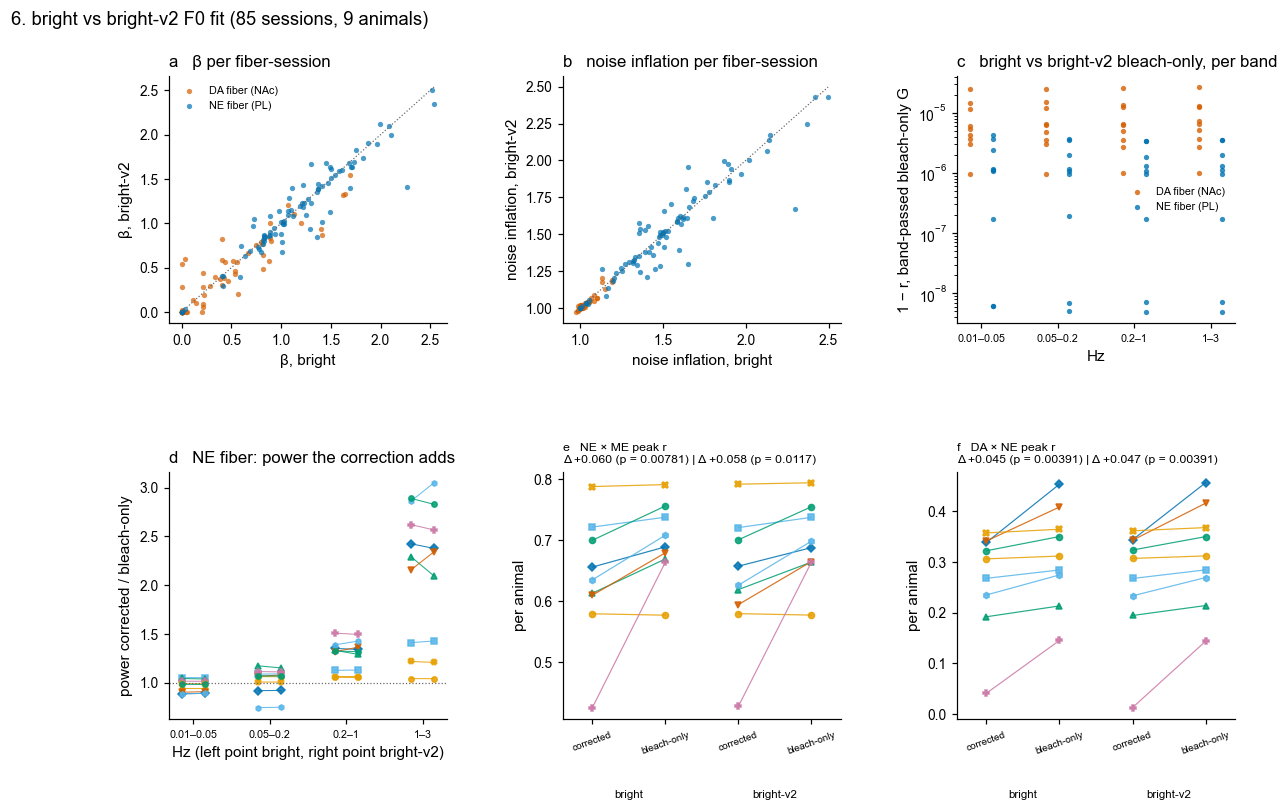

In [25]:
fig = plt.figure(figsize=(12.5, 7.4))
gs = GridSpec(2, 3, figure=fig, wspace=0.42, hspace=0.6, top=0.9)

for k, (col, label, letter) in enumerate((("beta", "β", "a"), ("noise_inflation", "noise inflation", "b"))):
    ax = fig.add_subplot(gs[0, k])
    for role in ROLES:
        d = v2_sess[v2_sess["role"] == role]
        ax.scatter(d[f"{col}_v1"], d[f"{col}_v2"], s=12, color=SENSOR_COLOR[role], alpha=0.7, lw=0, label=ROLE_LABEL[role])
    lim = [min(v2_sess[f"{col}_v1"].min(), v2_sess[f"{col}_v2"].min()), max(v2_sess[f"{col}_v1"].max(), v2_sess[f"{col}_v2"].max())]
    ax.plot(lim, lim, color=PALETTE["neutral"], lw=0.8, ls=":")
    ax.set_xlabel(f"{label}, bright")
    ax.set_ylabel(f"{label}, bright-v2")
    ax.set_title(f"{letter}   {label} per fiber-session", loc="left")
    if k == 0:
        ax.legend(fontsize=7)
    style_ax(ax)

ax = fig.add_subplot(gs[0, 2])
for j, role in enumerate(ROLES):
    a = v2_animal[role]
    for i, band in enumerate(BANDS):
        v = 1 - a[f"bleach r v1 × v2|{band}"]
        x = i + (j - 0.5) * 0.3
        ax.scatter(np.full(len(v), x), v, s=12, color=SENSOR_COLOR[role], lw=0, alpha=0.8, label=ROLE_LABEL[role] if i == 0 else None)
ax.set_xticks(range(len(BANDS)))
ax.set_xticklabels(list(BANDS), fontsize=7)
ax.set_xlabel("Hz")
ax.set_yscale("log")
ax.set_ylabel("1 − r, band-passed bleach-only G")
ax.set_title("c   bright vs bright-v2 bleach-only, per band", loc="left")
ax.legend(fontsize=7)
style_ax(ax)

ax = fig.add_subplot(gs[1, 0])
a = v2_animal["ne"]
for i, band in enumerate(BANDS):
    for s in a.index:
        ax.plot([i - 0.15, i + 0.15], [a.loc[s, f"ratio v1|{band}"], a.loc[s, f"ratio v2|{band}"]], "-", color=STYLES[s][0],
                marker=STYLES[s][1], ms=3.5, lw=0.7, alpha=0.85)
ax.axhline(1, color=PALETTE["neutral"], lw=0.8, ls=":")
ax.set_xticks(range(len(BANDS)))
ax.set_xticklabels(list(BANDS), fontsize=7)
ax.set_xlabel("Hz (left point bright, right point bright-v2)")
ax.set_ylabel("power corrected / bleach-only")
ax.set_title("d   NE fiber: power the correction adds", loc="left")
style_ax(ax)

for k, (m, letter) in enumerate((("ne × ME peak r", "e"), ("DA × NE peak r", "f"))):
    ax = fig.add_subplot(gs[1, k + 1])
    for s in down_animal.index:
        y = [down_animal.loc[s, f"{m}|corrected"], down_animal.loc[s, f"{m}|bleach"],
             down2_animal.loc[s, f"{m}|corrected"], down2_animal.loc[s, f"{m}|bleach"]]
        ax.plot([0, 1], y[:2], "-", color=STYLES[s][0], marker=STYLES[s][1], ms=4, lw=0.8, alpha=0.85)
        ax.plot([2, 3], y[2:], "-", color=STYLES[s][0], marker=STYLES[s][1], ms=4, lw=0.8, alpha=0.85)
    ax.set_xticks(range(4))
    ax.set_xticklabels(["corrected", "bleach-only", "corrected", "bleach-only"], fontsize=6.5, rotation=20)
    ax.text(0.5, -0.32, "bright", ha="center", transform=ax.get_xaxis_transform(), fontsize=7.5)
    ax.text(2.5, -0.32, "bright-v2", ha="center", transform=ax.get_xaxis_transform(), fontsize=7.5)
    ax.set_xlim(-0.4, 3.4)
    ax.set_ylabel("per animal")
    r1, r2 = down_table.set_index("measure").loc[m], down2_table.set_index("measure").loc[m]
    ax.set_title(f"{letter}   {m.replace('ne ', 'NE ')}\nΔ {r1['difference']:+.3f} (p {st.fmt_p(r1['p'])}) | Δ {r2['difference']:+.3f} (p {st.fmt_p(r2['p'])})",
                 loc="left", fontsize=8)
    style_ax(ax)
fig.suptitle(f"6. bright vs bright-v2 F0 fit ({len(pairs)} sessions, {N_ANIMALS} animals)", x=0.01, ha="left")
save_fig(fig, "fip_18_6_bright_v2", fig_dir=FIG_DIR, save=SAVE_FIG)
plt.show()

## 7. Numbers

In [26]:
print(f"Sessions: {len(pairs)} ({N_ANIMALS} animals); processed NWBs from {sorted(nwb_loc.loc[[p['session'] for p in pairs], 'processed'].unique())}")
print(f"Check: corrected trace reproduced from the stages and β to {rep.max():.0e}; curated vs NWB corrected r (median) DA {r_cur['r_da'].median():.4f}, NE {r_cur['r_ne'].median():.4f}")
print()
for role in ROLES:
    d = qc_g[qc_g["role"] == role]
    print(f"{ROLE_LABEL[role]}: β median {d['beta'].median():.2f} (IQR {d['beta'].quantile(0.25):.2f}–{d['beta'].quantile(0.75):.2f}); "
          f"β = 0 in {int(d['beta_zero'].sum())} of {len(d)} fiber-sessions; noise inflation median {d['noise_inflation'].median():.2f}")
    ba = band_animal[role]
    print("   per band (median over animals):  " + "; ".join(
        f"{b}: coh {ba[f'coh|{b}'].median():.3f}, β {ba[f'beta|{b}'].median():.2f}, power ratio {ba[f'ratio|{b}'].median():.2f}" for b in BANDS))
    ra = resp_animal[role]
    print(f"   at ME onsets (% dF/F): Iso {ra['resp|Iso bleach'].mean():+.3f}, R {ra['resp|R bleach'].mean():+.3f}, "
          f"G bleach-only {ra['resp|G bleach'].mean():+.3f}, G corrected {ra['resp|G corrected'].mean():+.3f}; "
          f"peak r with ME: Iso {ra['xcpeak|Iso bleach'].mean():.3f}, G bleach-only {ra['xcpeak|G bleach'].mean():.3f}, G corrected {ra['xcpeak|G corrected'].mean():.3f}")
print()
print(f"Fiber events: {len(flagged)} fiber-sessions ({flagged['session'].nunique()} sessions) with iso above {EVENT_SD:.0f} robust SD")
print()
print(down_table.to_string(index=False, float_format=lambda v: f"{v:.3g}"))
print()
for role in ROLES:
    d, a = v2_sess[v2_sess["role"] == role], v2_animal[role]
    print(f"bright-v2, {ROLE_LABEL[role]}: β median {d['beta_v2'].median():.2f} (bright {d['beta_v1'].median():.2f}); "
          f"noise inflation {d['noise_inflation_v2'].median():.2f} (bright {d['noise_inflation_v1'].median():.2f}); power ratio by band "
          + "; ".join(f"{b}: {a[f'ratio v2|{b}'].median():.2f} ({a[f'ratio v1|{b}'].median():.2f})" for b in BANDS))
print(down2_table.to_string(index=False, float_format=lambda v: f"{v:.3g}"))

Sessions: 85 (9 animals); processed NWBs from ['2026-11-10', '2026-11-11']
Check: corrected trace reproduced from the stages and β to 7e-17; curated vs NWB corrected r (median) DA 0.9986, NE 0.9941

DA fiber (NAc): β median 0.03 (IQR 0.00–0.53); β = 0 in 41 of 85 fiber-sessions; noise inflation median 1.00
   per band (median over animals):  0.01–0.05: coh 0.124, β 1.02, power ratio 1.00; 0.05–0.2: coh 0.218, β 0.97, power ratio 1.00; 0.2–1: coh 0.157, β -3.27, power ratio 1.00; 1–3: coh 0.052, β -0.76, power ratio 1.00
   at ME onsets (% dF/F): Iso +0.149, R -0.001, G bleach-only +0.624, G corrected +0.519; peak r with ME: Iso 0.195, G bleach-only 0.335, G corrected 0.328
NE fiber (PL): β median 1.11 (IQR 0.83–1.49); β = 0 in 3 of 85 fiber-sessions; noise inflation median 1.50
   per band (median over animals):  0.01–0.05: coh 0.140, β 0.75, power ratio 0.98; 0.05–0.2: coh 0.089, β -0.55, power ratio 1.07; 0.2–1: coh 0.057, β -0.34, power ratio 1.32; 1–3: coh 0.027, β -0.01, power rat